# Objective

This notebook implements a plain Maskable Proximal Policy Optimization (PPO) model for offline ground-station communication scheduling.

The objective is to establish a reinforcement learning baseline and investigate whether PPO can learn an effective request-selection policy without incorporating bee-inspired features.

# Environment Setup

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


### Load Shared Package

In [2]:
from pathlib import Path
import sys

PACKAGE_ROOT = Path("/content/drive/MyDrive/BEE/shared_v2")

SRC_DIR = PACKAGE_ROOT / "src"

assert PACKAGE_ROOT.exists(), (f"shared_v2 was not found at: {PACKAGE_ROOT}")

assert SRC_DIR.exists(), (f"Source folder was not found at: {SRC_DIR}")

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print("Shared package loaded from:", PACKAGE_ROOT)

Shared package loaded from: /content/drive/MyDrive/BEE/shared_v2


### check the shared package structure

In [3]:
from pathlib import Path

PACKAGE_ROOT = Path("/content/drive/MyDrive/BEE/shared_v2")

required_paths = [
    "data/raw",
    "data/processed",
    "src/placement.py",
    "src/environment.py",
    "src/validator.py",
    "src/experiment_config.py",
    "src/experiment_utils.py",
    "metadata/shared_config.json",
    "metadata/data_manifest.json",
    "metadata/package_manifest.json",
    "tests/smoke_test_results.json",
    "README.md"
]

for path in required_paths:
    full_path = PACKAGE_ROOT / path
    status = "FOUND" if full_path.exists() else "MISSING"
    print(f"{status}: {path}")

FOUND: data/raw
FOUND: data/processed
FOUND: src/placement.py
FOUND: src/environment.py
FOUND: src/validator.py
FOUND: src/experiment_config.py
FOUND: src/experiment_utils.py
FOUND: metadata/shared_config.json
FOUND: metadata/data_manifest.json
FOUND: metadata/package_manifest.json
FOUND: tests/smoke_test_results.json
FOUND: README.md


### Import the shared modules

In [4]:
from experiment_config import (
    PACKAGE_VERSION,
    CANONICAL_SPLIT,
    ROBUSTNESS_FOLDS,
    TRAINING_SEEDS,
    EVALUATION_SEEDS,
    MAX_REQUESTS,
    MAX_STEPS,
    TOTAL_TIMESTEPS,
    CHECKPOINT_FREQUENCY,
    PPO_CONFIG,
    RESULT_COLUMNS,
    SUMMARY_METRICS,
)

from experiment_utils import (
    load_shared_data,
    select_weeks,
    make_base_environment,
    mask_function,
    validate_environment_schedule,
    evaluate_maskable_policy,
)

(
    request_table,
    visibility_table,
    maintenance_table,
) = load_shared_data(PACKAGE_ROOT)

print("Package version:", PACKAGE_VERSION)
print("Requests:", request_table.shape)
print("Visibility periods:", visibility_table.shape)
print("Maintenance intervals:", maintenance_table.shape)
print("Weeks:",sorted(request_table["week_key"].unique()),)

Package version: shared_v2
Requests: (1452, 21)
Visibility periods: (14699, 17)
Maintenance intervals: (1798, 6)
Weeks: ['W10_2018', 'W20_2018', 'W30_2018', 'W40_2018', 'W50_2018']


In [5]:
import json

MANIFEST_PATH = (PACKAGE_ROOT / "metadata" / "package_manifest.json")

assert MANIFEST_PATH.exists(), (f"Package manifest not found: {MANIFEST_PATH}")

with open(MANIFEST_PATH, "r") as file:
    package_manifest = json.load(file)

assert PACKAGE_VERSION == "shared_v2", (f"Incorrect imported package: {PACKAGE_VERSION}")

assert (package_manifest["package_version"] == "shared_v2"), ("The package manifest does not identify shared_v2.")

print("Package verification passed.")
print("Package version:", package_manifest["package_version"],)

print("Shared module hashes:")

for filename, file_hash in (
    package_manifest["modules"].items()
):
    print(f"  {filename}: {file_hash}")

Package verification passed.
Package version: shared_v2
Shared module hashes:
  environment.py: bb5cc62f3dd23fff749b8591a7ce2a994abd05b220f66e90fbcb5544d7aebda7
  experiment_config.py: 9704cd0c1000ff58fa9afb9eceaf18f995c9f0090c24d3213c2722a0c810269f
  experiment_utils.py: a92190c7a0d02c641b2967886821cfe716220ec8297cc4d3bb59d9e58c0b80c1
  placement.py: 6579b898b1c7047ea0ce9b04a55cdaec3ecde9408b694aa326f48c1d4e9fc4fd
  validator.py: b1dcbb306d180fd723b31f078ccb6f1b1817bf7f23d04e49ee181e8b53badcf3


### Inspect the configuration and datasets

In [6]:
print("PACKAGE VERSION:", PACKAGE_VERSION)

print("\nCANONICAL SPLIT:")
print(CANONICAL_SPLIT)

print("\nROBUSTNESS FOLDS:")
print(ROBUSTNESS_FOLDS)

print("\nTRAINING SEEDS:", TRAINING_SEEDS)
print("EVALUATION SEEDS:", EVALUATION_SEEDS)

print("\nMAX REQUESTS:", MAX_REQUESTS)
print("MAX STEPS:", MAX_STEPS)
print("TOTAL TIMESTEPS:", TOTAL_TIMESTEPS)
print("CHECKPOINT FREQUENCY:", CHECKPOINT_FREQUENCY)

print("\nPPO CONFIGURATION:")
print(PPO_CONFIG)

print("\nDATASET SHAPES:")
print("Requests:", request_table.shape)
print("Visibility:", visibility_table.shape)
print("Maintenance:", maintenance_table.shape)

print("\nAVAILABLE WEEKS:")
print(sorted(request_table["week_key"].unique()))

print("\nREQUEST TABLE COLUMNS:")
print(request_table.columns.tolist())

PACKAGE VERSION: shared_v2

CANONICAL SPLIT:
{'training_weeks': ['W10_2018', 'W20_2018', 'W30_2018'], 'validation_week': 'W40_2018', 'test_week': 'W50_2018'}

ROBUSTNESS FOLDS:
[{'fold': 1, 'training_weeks': ['W20_2018', 'W30_2018', 'W40_2018', 'W50_2018'], 'test_week': 'W10_2018'}, {'fold': 2, 'training_weeks': ['W10_2018', 'W30_2018', 'W40_2018', 'W50_2018'], 'test_week': 'W20_2018'}, {'fold': 3, 'training_weeks': ['W10_2018', 'W20_2018', 'W40_2018', 'W50_2018'], 'test_week': 'W30_2018'}, {'fold': 4, 'training_weeks': ['W10_2018', 'W20_2018', 'W30_2018', 'W50_2018'], 'test_week': 'W40_2018'}, {'fold': 5, 'training_weeks': ['W10_2018', 'W20_2018', 'W30_2018', 'W40_2018'], 'test_week': 'W50_2018'}]

TRAINING SEEDS: [42, 123, 456]
EVALUATION SEEDS: [1001, 2002, 3003, 4004, 5005]

MAX REQUESTS: 333
MAX STEPS: 1000
TOTAL TIMESTEPS: 25000
CHECKPOINT FREQUENCY: 500

PPO CONFIGURATION:
{'learning_rate': 0.0003, 'n_steps': 256, 'batch_size': 64, 'n_epochs': 10, 'gamma': 0.99, 'gae_lambda': 0.

### Inspect data distribution and quality

In [7]:
print("REQUESTS PER WEEK:")
print(request_table.groupby("week_key").size())

print("\nMISSING VALUES:")
print("Requests:", request_table.isnull().sum().sum())
print("Visibility:", visibility_table.isnull().sum().sum())
print("Maintenance:", maintenance_table.isnull().sum().sum())

print("\nDUPLICATE REQUESTS:")
print(request_table.duplicated(
    subset=["week_key", "track_id"]
).sum())

print("\nREQUEST DURATION SUMMARY:")
print(request_table[
    ["duration_seconds", "minimum_duration_seconds",
     "setup_seconds", "teardown_seconds"]
].describe())

print("\nREQUEST SAMPLE:")
display(request_table.head(3))

REQUESTS PER WEEK:
week_key
W10_2018    257
W20_2018    294
W30_2018    293
W40_2018    333
W50_2018    275
dtype: int64

MISSING VALUES:
Requests: 0
Visibility: 0
Maintenance: 0

DUPLICATE REQUESTS:
0

REQUEST DURATION SUMMARY:
       duration_seconds  minimum_duration_seconds  setup_seconds  \
count       1452.000000               1452.000000    1452.000000   
mean       17580.743802              15265.785124    3293.181818   
std        10648.115988               8076.495929     641.963788   
min         3600.000000               3600.000000    1800.000000   
25%         9000.000000               9000.000000    3600.000000   
50%        14400.000000              14400.000000    3600.000000   
75%        28800.000000              23040.000000    3600.000000   
max        36000.000000              28800.000000    7200.000000   

       teardown_seconds  
count       1452.000000  
mean         966.942149  
std          313.418297  
min          900.000000  
25%          900.000000  
50

,week_key,week,year,subject,user,track_id,duration_seconds,minimum_duration_seconds,setup_seconds,teardown_seconds,...,time_window_end,number_of_resource_options,number_of_physical_antennas,number_of_visibility_periods,total_visible_seconds,resource_options,duration_flexibility_ratio,placement_scarcity_raw,resource_scarcity_raw,static_resource_contention
0,W10_2018,10,2018,521,521_0,fc9bbb54-3-1,3600,3600,3600,900,...,1520471551,2,2,6,121202,"[DSS-34, DSS-36]",33.667222,0.166667,0.5,1109.5
1,W10_2018,10,2018,521,521_0,fc9bbb54-3-2,3600,3600,3600,900,...,1520657096,2,2,6,175931,"[DSS-34, DSS-36]",48.869722,0.166667,0.5,1109.5
2,W10_2018,10,2018,521,521_0,fc9bbb54-3-3,3600,3600,3600,900,...,1520842641,2,2,6,172131,"[DSS-34, DSS-36]",47.814167,0.166667,0.5,1109.5


# Create The Environment

## Section 1 — Create and verify the environment

In [8]:
!pip install sb3-contrib stable-baselines3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [sb3-contrib]


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import inspect
import random
import torch

from environment import BEEGroundStationEnv

from stable_baselines3 import PPO
from sb3_contrib import MaskablePPO
from sb3_contrib.common.wrappers import ActionMasker

from stable_baselines3.common.monitor import Monitor

print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("Maskable PPO imported successfully.")

NumPy: 2.4.6
PyTorch: 2.14.1+cpu
Maskable PPO imported successfully.


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Inspect the shared environment functions

In [10]:
print("Environment constructor:")
print(inspect.signature(BEEGroundStationEnv))

print("\nBase environment helper:")
print(inspect.signature(make_base_environment))

print("\nAction mask helper:")
print(inspect.signature(mask_function))

print("\nSchedule validation helper:")
print(inspect.signature(validate_environment_schedule))

print("\nPolicy evaluation helper:")
print(inspect.signature(evaluate_maskable_policy))

Environment constructor:
(requests, visibility_periods, maintenance, include_bee_features=False, seed=42, max_requests=333, max_steps=1000, shuffle_requests=True)

Base environment helper:
(requests, visibility, maintenance, seed=42, shuffle_requests=True)

Action mask helper:
(environment)

Schedule validation helper:
(environment)

Policy evaluation helper:
(model, environment, week_key, seed, method)


## Section 2 — Create the baseline environment

### Environment implementation

In [11]:
training_weeks = CANONICAL_SPLIT["training_weeks"]

train_requests, train_visibility, train_maintenance = select_weeks(
    request_table,
    visibility_table,
    maintenance_table,
    training_weeks
)

print("Training weeks:", training_weeks)
print("Training requests:", train_requests.shape)
print("Training visibility:", train_visibility.shape)
print("Training maintenance:", train_maintenance.shape)

print("\nRequests per week:")
print(train_requests.groupby("week_key").size())

Training weeks: ['W10_2018', 'W20_2018', 'W30_2018']
Training requests: (844, 21)
Training visibility: (8570, 17)
Training maintenance: (103, 6)

Requests per week:
week_key
W10_2018    257
W20_2018    294
W30_2018    293
dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Create the plain PPO environment

In [12]:
base_env = make_base_environment(
    requests=train_requests,
    visibility=train_visibility,
    maintenance=train_maintenance,
    seed=42,
    shuffle_requests=True
)

env = ActionMasker(base_env, mask_function)

print("Plain PPO environment created successfully.")
print("Bee features:", base_env.include_bee_features)
print("Request features:", base_env.request_feature_count)
print("Global features:", base_env.global_feature_count)
print("Observation space:", base_env.observation_space.shape)
print("Action space:", base_env.action_space)

Plain PPO environment created successfully.
Bee features: False
Request features: 9
Global features: 4
Observation space: (3001,)
Action space: Discrete(333)


### Verify observation and action masking

In [13]:
obs, info = env.reset(
    seed=42,
    options={"week_key": "W10_2018"}
)

action_mask = env.action_masks()

print("Observation shape:", obs.shape)
print("Expected shape:", 333 * 9 + 4)

print("Observation dtype:", obs.dtype)
print("Observation minimum:", obs.min())
print("Observation maximum:", obs.max())

print("\nAction mask shape:", action_mask.shape)
print("Valid actions:", action_mask.sum())
print("Invalid actions:", len(action_mask) - action_mask.sum())

assert obs.shape == (3001,)
assert obs.dtype == np.float32
assert np.isfinite(obs).all()
assert np.all((obs >= 0) & (obs <= 1))
assert action_mask.shape == (333,)
assert action_mask.sum() > 0

print("\nAll initial environment checks passed.")

Observation shape: (3001,)
Expected shape: 3001
Observation dtype: float32
Observation minimum: 0.0
Observation maximum: 1.0

Action mask shape: (333,)
Valid actions: 257
Invalid actions: 76

All initial environment checks passed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Section 3 — Environment testing

### Test reproducibility

In [14]:
obs1, info1 = env.reset(
    seed=42,
    options={"week_key": "W10_2018"}
)

mask1 = env.action_masks()

obs2, info2 = env.reset(
    seed=42,
    options={"week_key": "W10_2018"}
)

mask2 = env.action_masks()

print("Same observations:", np.array_equal(obs1, obs2))
print("Same action masks:", np.array_equal(mask1, mask2))
print("Same week:", info1["week_key"] == info2["week_key"])

assert np.array_equal(obs1, obs2)
assert np.array_equal(mask1, mask2)

print("\nReproducibility test passed.")

Same observations: True
Same action masks: True
Same week: True

Reproducibility test passed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Test reset behavior

In [15]:
obs, info = env.reset(
    seed=123,
    options={"week_key": "W20_2018"}
)

print("Selected week:", info["week_key"])
print("Number of requests:", info["number_of_requests"])
print("Scheduled actions:", len(base_env.scheduled_actions))
print("Schedule length:", len(base_env.schedule))
print("Step count:", base_env.step_count)
print("Valid actions:", env.action_masks().sum())

assert info["week_key"] == "W20_2018"
assert len(base_env.scheduled_actions) == 0
assert len(base_env.schedule) == 0
assert base_env.step_count == 0

print("\nReset test passed.")

Selected week: W20_2018
Number of requests: 294
Scheduled actions: 0
Schedule length: 0
Step count: 0
Valid actions: 294

Reset test passed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Test one valid scheduling action

In [16]:
valid_actions = np.flatnonzero(env.action_masks())

action = int(valid_actions[0])

obs, reward, terminated, truncated, info = env.step(action)

print("Selected action:", action)
print("Valid action:", info["valid_action"])
print("Reward:", reward)
print("Scheduled requests:", len(base_env.schedule))
print("Terminated:", terminated)
print("Truncated:", truncated)

assert info["valid_action"] is True
assert len(base_env.schedule) == 1
assert reward >= 0

print("\nScheduling action test passed.")

Selected action: 0
Valid action: True
Reward: 1.5
Scheduled requests: 1
Terminated: False
Truncated: False

Scheduling action test passed.


### Validate the generated schedule

In [17]:
validation_result = validate_environment_schedule(base_env)

print("Validation result:")
print(validation_result)

Validation result:
{'duplicate_request_violations': 0, 'duration_violations': 0, 'visibility_violations': 0, 'maintenance_violations': 0, 'antenna_overlap_violations': 0, 'resource_violations': 0, 'constraint_violations': 0}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Train Maskable PPO

## Create the validation environment and training callback

In [ ]:
from pathlib import Path
from stable_baselines3.common.callbacks import BaseCallback

# Create output folders
OUTPUT_DIR = Path("/content/drive/MyDrive/BEE/member2_plain_ppo")
CHECKPOINT_DIR = OUTPUT_DIR / "plain_ppo_models"
VALIDATION_DIR = OUTPUT_DIR / "plain_ppo_validation"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

# Recreate a fresh training environment
train_base_env = make_base_environment(
    train_requests,
    train_visibility,
    train_maintenance,
    seed=42,
    shuffle_requests=True
)

train_env = ActionMasker(train_base_env, mask_function)

# Create a separate validation environment using W40 only
val_requests, val_visibility, val_maintenance = select_weeks(
    request_table,
    visibility_table,
    maintenance_table,
    ["W40_2018"]
)

val_base_env = make_base_environment(
    val_requests,
    val_visibility,
    val_maintenance,
    seed=1001,
    shuffle_requests=True
)

val_env = ActionMasker(val_base_env, mask_function)


class PlainPPOCallback(BaseCallback):

    def __init__(self, validation_env, checkpoint_dir, validation_dir):
        super().__init__(verbose=1)
        self.validation_env = validation_env
        self.checkpoint_dir = Path(checkpoint_dir)
        self.validation_dir = Path(validation_dir)
        self.validation_rows = []

    def _on_step(self):

        if self.num_timesteps % CHECKPOINT_FREQUENCY != 0:
            return True

        # Save checkpoint
        checkpoint_path = self.checkpoint_dir / f"plain_ppo_{self.num_timesteps}"
        self.model.save(str(checkpoint_path))

        # Evaluate on W40
        metrics, schedule, validation = evaluate_maskable_policy(
            model=self.model,
            environment=self.validation_env,
            week_key="W40_2018",
            seed=1001,
            method="plain_maskable_ppo"
        )

        row = dict(metrics)
        row["timesteps"] = self.num_timesteps

        for key, value in validation.items():
            row[f"validation_{key}"] = value

        self.validation_rows.append(row)

        # Save validation progress
        results = pd.DataFrame(self.validation_rows)
        results.to_csv(
            self.validation_dir / "plain_ppo_validation_progress.csv",
            index=False
        )

        print(
            f"Timesteps: {self.num_timesteps} | "
            f"Fulfillment: {metrics.get('duration_fulfillment')} | "
            f"Violations: {validation.get('constraint_violations')}"
        )

        return True


callback = PlainPPOCallback(
    validation_env=val_base_env,
    checkpoint_dir=CHECKPOINT_DIR,
    validation_dir=VALIDATION_DIR
)

print("Validation environment:", type(callback.validation_env).__name__)
print("Has schedule:", hasattr(callback.validation_env, "schedule"))
print("Has action_masks:", hasattr(callback.validation_env, "action_masks"))

print("Training environment ready.")
print("Validation week:", "W40_2018")
print("Training requests:", len(train_requests))
print("Validation requests:", len(val_requests))
print("Checkpoint frequency:", CHECKPOINT_FREQUENCY)

Validation environment: BEEGroundStationEnv
Has schedule: True
Has action_masks: True
Training environment ready.
Validation week: W40_2018
Training requests: 844
Validation requests: 333
Checkpoint frequency: 500


## Train Plain Maskable PPO

In [ ]:
from sb3_contrib import MaskablePPO
import time

# Initialize the model
model = MaskablePPO(
    policy="MlpPolicy",
    env=train_env,
    learning_rate=PPO_CONFIG["learning_rate"],
    n_steps=PPO_CONFIG["n_steps"],
    batch_size=PPO_CONFIG["batch_size"],
    n_epochs=PPO_CONFIG["n_epochs"],
    gamma=PPO_CONFIG["gamma"],
    gae_lambda=PPO_CONFIG["gae_lambda"],
    clip_range=PPO_CONFIG["clip_range"],
    ent_coef=PPO_CONFIG["ent_coef"],
    vf_coef=PPO_CONFIG["vf_coef"],
    max_grad_norm=PPO_CONFIG["max_grad_norm"],
    seed=42,
    verbose=1,
    tensorboard_log=str(OUTPUT_DIR / "tensorboard")
)

start_time = time.time()

model.learn(
    total_timesteps=TOTAL_TIMESTEPS,
    callback=callback
)

training_time = time.time() - start_time

final_model_path = CHECKPOINT_DIR / "plain_ppo_final"
model.save(str(final_model_path))

print("\nTraining completed.")
print("Total timesteps:", model.num_timesteps)
print(f"Training time: {training_time:.2f} seconds")
print("Final model saved:", final_model_path)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to /content/drive/MyDrive/BEE/member2_plain_ppo/tensorboard/MaskablePPO_3


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 199      |
|    ep_rew_mean     | 296      |
| time/              |          |
|    fps             | 14       |
|    iterations      | 1        |
|    time_elapsed    | 17       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Timesteps: 500 | Fulfillment: 0.5486038335796498 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (237 outputs left out)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 216        |
|    ep_rew_mean          | 322        |
| time/                   |            |
|    fps                  | 8          |
|    iterations           | 98         |
|    time_elapsed         | 2853       |
|    total_timesteps      | 25088      |
| train/                  |            |
|    approx_kl            | 0.08298369 |
|    clip_fraction        | 0.493      |
|    clip_range           | 0.2        |
|    entropy_loss         | -3.58      |
|    explained_variance   | 5.96e-08   |
|    learning_rate        | 0.0003     |
|    loss                 | 251        |
|    n_updates            | 970        |
|    policy_gradient_loss | -0.0665    |
|    value_loss           | 418        |
----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Training completed.
Total timesteps: 25088
Training time: 2853.93 seconds
Final model saved: /content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_models/plain_ppo_final


## Evaluate the final model

In [ ]:
evaluation_seeds = EVALUATION_SEEDS

evaluation_results = []
evaluation_schedules = {}

for seed in evaluation_seeds:

    metrics, schedule, validation = evaluate_maskable_policy(
        model=model,
        environment=val_base_env,
        week_key="W40_2018",
        seed=seed,
        method="plain_maskable_ppo"
    )

    evaluation_results.append(metrics)
    evaluation_schedules[seed] = schedule

    print(f"\nEvaluation seed: {seed}")
    print("Duration fulfillment:", metrics["duration_fulfillment"])
    print("Minimum satisfaction:", metrics["minimum_satisfaction_rate"])
    print("Mission fairness:", metrics["mission_fairness"])
    print("Runtime:", metrics["runtime_seconds"])
    print("Constraint violations:", validation["constraint_violations"])

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df.to_csv(
    OUTPUT_DIR / "plain_ppo_final_evaluation.csv",
    index=False
)

print("\nEvaluation completed.")
display(evaluation_df)


Evaluation seed: 1001
Duration fulfillment: 0.5247554429537501
Minimum satisfaction: 0.6366366366366366
Mission fairness: 0.8804031638736756
Runtime: 17.770700669000234
Constraint violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Evaluation seed: 2002
Duration fulfillment: 0.5218441104777259
Minimum satisfaction: 0.6516516516516516
Mission fairness: 0.8576631935287274
Runtime: 18.41749814800005
Constraint violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Evaluation seed: 3003
Duration fulfillment: 0.5240209720862683
Minimum satisfaction: 0.6516516516516516
Mission fairness: 0.8733639681162612
Runtime: 19.117976983000062
Constraint violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Evaluation seed: 4004
Duration fulfillment: 0.5283321497348099
Minimum satisfaction: 0.6546546546546547
Mission fairness: 0.8371155302642929
Runtime: 18.49854299000026
Constraint violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Evaluation seed: 5005
Duration fulfillment: 0.5331063703191877
Minimum satisfaction: 0.6696696696696697
Mission fairness: 0.8624669707239907
Runtime: 20.068995262000044
Constraint violations: 0

Evaluation completed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,week_key,number_of_requests,scheduled_requests,allocated_hours,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness,constraint_violations,method,seed,episode_reward,steps,runtime_seconds
0,W40_2018,333,212,911.342778,0.524755,0.636637,0.537538,825.357222,0.880403,0,plain_maskable_ppo,1001,315.239965,212,17.770701
1,W40_2018,333,217,906.286667,0.521844,0.651652,0.534535,830.413333,0.857663,0,plain_maskable_ppo,2002,322.194049,217,18.417498
2,W40_2018,333,217,910.067222,0.524021,0.651652,0.552553,826.632778,0.873364,0,plain_maskable_ppo,3003,322.022646,217,19.117977
3,W40_2018,333,218,917.554444,0.528332,0.654655,0.564565,819.145556,0.837116,0,plain_maskable_ppo,4004,324.125729,218,18.498543
4,W40_2018,333,223,925.845833,0.533106,0.669670,0.582583,810.854167,0.862467,0,plain_maskable_ppo,5005,331.968229,223,20.068995


## Save evaluation outputs

In [ ]:
# Create schedules folder
SCHEDULE_DIR = OUTPUT_DIR / "plain_ppo_schedules"
SCHEDULE_DIR.mkdir(parents=True, exist_ok=True)

# Save each independently validated schedule
for seed, schedule in evaluation_schedules.items():
    schedule.to_csv(
        SCHEDULE_DIR / f"plain_ppo_W40_seed_{seed}.csv",
        index=False
    )

# Calculate average metrics
summary_metrics = [
    "duration_fulfillment",
    "minimum_satisfaction_rate",
    "full_satisfaction_rate",
    "mission_fairness",
    "runtime_seconds",
    "episode_reward"
]

evaluation_summary = evaluation_df[summary_metrics].mean().to_frame(
    name="mean"
).T

evaluation_summary.to_csv(
    OUTPUT_DIR / "plain_ppo_validation_summary.csv",
    index=False
)

print("Evaluation schedules and summary saved.")
display(evaluation_summary)

Evaluation schedules and summary saved.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,mission_fairness,runtime_seconds,episode_reward
mean,0.526412,0.652853,0.554354,0.862203,18.774743,323.110124


# Cross-week robustness experiments

# Training The 5 folds

## Fold 1
This fold trains on W20, W30, W40, W50 and tests on W10.

In [ ]:
# Cross-week output folders
CROSS_WEEK_MODEL_DIR = OUTPUT_DIR / "plain_ppo_cross_week_models"
CROSS_WEEK_SCHEDULE_DIR = OUTPUT_DIR / "plain_ppo_cross_week_schedules"

CROSS_WEEK_MODEL_DIR.mkdir(parents=True, exist_ok=True)
CROSS_WEEK_SCHEDULE_DIR.mkdir(parents=True, exist_ok=True)

# Fold 1
fold = ROBUSTNESS_FOLDS[0]

fold_train_weeks = fold["training_weeks"]
fold_test_week = fold["test_week"]

print("Training weeks:", fold_train_weeks)
print("Held-out test week:", fold_test_week)

# Prepare training data
fold_train_requests, fold_train_visibility, fold_train_maintenance = select_weeks(
    request_table,
    visibility_table,
    maintenance_table,
    fold_train_weeks
)

# Create training environment
fold_train_base_env = make_base_environment(
    fold_train_requests,
    fold_train_visibility,
    fold_train_maintenance,
    seed=42,
    shuffle_requests=True
)

fold_train_env = ActionMasker(fold_train_base_env, mask_function)

# Initialize fresh PPO model
fold_model = MaskablePPO(
    policy="MlpPolicy",
    env=fold_train_env,
    **PPO_CONFIG,
    seed=42,
    verbose=1
)

# Train
fold_start_time = time.time()

fold_model.learn(total_timesteps=TOTAL_TIMESTEPS)

fold_training_time = time.time() - fold_start_time

# Save model
fold_model_path = CROSS_WEEK_MODEL_DIR / "fold_1_train_seed_42"
fold_model.save(str(fold_model_path))

print("\nFold 1 training completed.")
print("Total timesteps:", fold_model.num_timesteps)
print(f"Training time: {fold_training_time:.2f} seconds")
print("Saved model:", fold_model_path)

Training weeks: ['W20_2018', 'W30_2018', 'W40_2018', 'W50_2018']
Held-out test week: W10_2018
Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 227      |
|    ep_rew_mean     | 339      |
| time/              |          |
|    fps             | 13       |
|    iterations      | 1        |
|    time_elapsed    | 19       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 225         |
|    ep_rew_mean          | 336         |
| time/                   |             |
|    fps                  | 13          |
|    iterations           | 2           |
|    time_elapsed         | 39          |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.007727064 |
|    clip_fraction        | 0.00117     |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.79       |
|    explained_variance   | -0.00423    |
|    learning_rate        | 0.0003      |
|    loss                 | 146         |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0401     |
|    value_loss           | 324         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (189 outputs left out)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 218         |
|    ep_rew_mean          | 325         |
| time/                   |             |
|    fps                  | 12          |
|    iterations           | 98          |
|    time_elapsed         | 1942        |
|    total_timesteps      | 25088       |
| train/                  |             |
|    approx_kl            | 0.025631271 |
|    clip_fraction        | 0.21        |
|    clip_range           | 0.2         |
|    entropy_loss         | -3.94       |
|    explained_variance   | 0.037       |
|    learning_rate        | 0.0003      |
|    loss                 | 57.3        |
|    n_updates            | 970         |
|    policy_gradient_loss | -0.0499     |
|    value_loss           | 287         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Fold 1 training completed.
Total timesteps: 25088
Training time: 1942.63 seconds
Saved model: /content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_cross_week_models/fold_1_train_seed_42


## Fold 2
This fold trains on W10, W30, W40, W50 and tests on W20.

In [ ]:
from stable_baselines3.common.callbacks import CheckpointCallback

In [ ]:
fold = ROBUSTNESS_FOLDS[1]

fold_train_weeks = fold["training_weeks"]
fold_test_week = fold["test_week"]

fold_train_requests, fold_train_visibility, fold_train_maintenance = select_weeks(
    request_table, visibility_table, maintenance_table, fold_train_weeks
)

fold_train_base_env = make_base_environment(
    fold_train_requests,
    fold_train_visibility,
    fold_train_maintenance,
    seed=42,
    shuffle_requests=True
)

fold_train_env = ActionMasker(fold_train_base_env, mask_function)

fold_model = MaskablePPO(
    policy="MlpPolicy",
    env=fold_train_env,
    **PPO_CONFIG,
    seed=42,
    verbose=1
)

fold_checkpoint_dir = CROSS_WEEK_MODEL_DIR / "fold_2_checkpoints"
fold_checkpoint_dir.mkdir(parents=True, exist_ok=True)

checkpoint_callback = CheckpointCallback(
    save_freq=5000,
    save_path=str(fold_checkpoint_dir),
    name_prefix="fold_2"
)

fold_start_time = time.time()

fold_model.learn(
    total_timesteps=TOTAL_TIMESTEPS,
    callback=checkpoint_callback
)

fold_training_time = time.time() - fold_start_time

fold_model_path = CROSS_WEEK_MODEL_DIR / "fold_2_train_seed_42"
fold_model.save(str(fold_model_path))

print("Fold 2 training completed.")
print("Total timesteps:", fold_model.num_timesteps)
print("Training time:", round(fold_training_time, 2), "seconds")
print("Saved model:", fold_model_path)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 199      |
|    ep_rew_mean     | 296      |
| time/              |          |
|    fps             | 15       |
|    iterations      | 1        |
|    time_elapsed    | 16       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 198          |
|    ep_rew_mean          | 296          |
| time/                   |              |
|    fps                  | 14           |
|    iterations           | 2            |
|    time_elapsed         | 35           |
|    total_timesteps      | 512          |
| train/                  |              |
|    approx_kl            | 0.0078543145 |
|    clip_fraction        | 0.00195      |
|    clip_range           | 0.2          |
|    entropy_loss         | -4.75        |
|    explained_variance   | -0.0171      |
|    learning_rate        | 0.0003       |
|    loss                 | 140          |
|    n_updates            | 10           |
|    policy_gradient_loss | -0.0407      |
|    value_loss           | 316          |
------------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (189 outputs left out)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 210          |
|    ep_rew_mean          | 312          |
| time/                   |              |
|    fps                  | 13           |
|    iterations           | 98           |
|    time_elapsed         | 1887         |
|    total_timesteps      | 25088        |
| train/                  |              |
|    approx_kl            | 0.0151013015 |
|    clip_fraction        | 0.0992       |
|    clip_range           | 0.2          |
|    entropy_loss         | -3.78        |
|    explained_variance   | 1.79e-07     |
|    learning_rate        | 0.0003       |
|    loss                 | 112          |
|    n_updates            | 970          |
|    policy_gradient_loss | -0.0401      |
|    value_loss           | 257          |
------------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 2 training completed.
Total timesteps: 25088
Training time: 1888.05 seconds
Saved model: /content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_cross_week_models/fold_2_train_seed_42


## Fold 3
This fold trains on W10, W20, W40, W50 and tests on W30.

In [ ]:
fold = ROBUSTNESS_FOLDS[2]

fold_train_weeks = fold["training_weeks"]
fold_test_week = fold["test_week"]

fold_train_requests, fold_train_visibility, fold_train_maintenance = select_weeks(
    request_table, visibility_table, maintenance_table, fold_train_weeks
)

fold_train_base_env = make_base_environment(
    fold_train_requests,
    fold_train_visibility,
    fold_train_maintenance,
    seed=42,
    shuffle_requests=True
)

fold_train_env = ActionMasker(fold_train_base_env, mask_function)

fold_model = MaskablePPO(
    policy="MlpPolicy",
    env=fold_train_env,
    **PPO_CONFIG,
    seed=42,
    verbose=1
)

fold_checkpoint_dir = CROSS_WEEK_MODEL_DIR / "fold_3_checkpoints"
fold_checkpoint_dir.mkdir(parents=True, exist_ok=True)

checkpoint_callback = CheckpointCallback(
    save_freq=5000,
    save_path=str(fold_checkpoint_dir),
    name_prefix="fold_3"
)

fold_start_time = time.time()

fold_model.learn(
    total_timesteps=TOTAL_TIMESTEPS,
    callback=checkpoint_callback
)

fold_training_time = time.time() - fold_start_time

fold_model_path = CROSS_WEEK_MODEL_DIR / "fold_3_train_seed_42"
fold_model.save(str(fold_model_path))

print("Fold 3 training completed.")
print("Total timesteps:", fold_model.num_timesteps)
print("Training time:", round(fold_training_time, 2), "seconds")
print("Saved model:", fold_model_path)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 199      |
|    ep_rew_mean     | 296      |
| time/              |          |
|    fps             | 15       |
|    iterations      | 1        |
|    time_elapsed    | 17       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 198          |
|    ep_rew_mean          | 296          |
| time/                   |              |
|    fps                  | 13           |
|    iterations           | 2            |
|    time_elapsed         | 37           |
|    total_timesteps      | 512          |
| train/                  |              |
|    approx_kl            | 0.0078543145 |
|    clip_fraction        | 0.00195      |
|    clip_range           | 0.2          |
|    entropy_loss         | -4.75        |
|    explained_variance   | -0.0171      |
|    learning_rate        | 0.0003       |
|    loss                 | 140          |
|    n_updates            | 10           |
|    policy_gradient_loss | -0.0407      |
|    value_loss           | 316          |
------------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (189 outputs left out)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 212         |
|    ep_rew_mean          | 316         |
| time/                   |             |
|    fps                  | 13          |
|    iterations           | 98          |
|    time_elapsed         | 1901        |
|    total_timesteps      | 25088       |
| train/                  |             |
|    approx_kl            | 0.019236092 |
|    clip_fraction        | 0.0816      |
|    clip_range           | 0.2         |
|    entropy_loss         | -3.87       |
|    explained_variance   | 4.17e-07    |
|    learning_rate        | 0.0003      |
|    loss                 | 172         |
|    n_updates            | 970         |
|    policy_gradient_loss | -0.038      |
|    value_loss           | 255         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 2 training completed.
Total timesteps: 25088
Training time: 1901.77 seconds
Saved model: /content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_cross_week_models/fold_3_train_seed_42


## Fold 4
This fold trains on W10, W20, W30, W50 and tests on W40.

In [ ]:
fold = ROBUSTNESS_FOLDS[3]

fold_train_weeks = fold["training_weeks"]
fold_test_week = fold["test_week"]

fold_train_requests, fold_train_visibility, fold_train_maintenance = select_weeks(
    request_table, visibility_table, maintenance_table, fold_train_weeks
)

fold_train_base_env = make_base_environment(
    fold_train_requests,
    fold_train_visibility,
    fold_train_maintenance,
    seed=42,
    shuffle_requests=True
)

fold_train_env = ActionMasker(fold_train_base_env, mask_function)

fold_model = MaskablePPO(
    policy="MlpPolicy",
    env=fold_train_env,
    **PPO_CONFIG,
    seed=42,
    verbose=1
)

fold_checkpoint_dir = CROSS_WEEK_MODEL_DIR / "fold_4_checkpoints"
fold_checkpoint_dir.mkdir(parents=True, exist_ok=True)

checkpoint_callback = CheckpointCallback(
    save_freq=5000,
    save_path=str(fold_checkpoint_dir),
    name_prefix="fold_4"
)

fold_start_time = time.time()

fold_model.learn(
    total_timesteps=TOTAL_TIMESTEPS,
    callback=checkpoint_callback
)

fold_training_time = time.time() - fold_start_time

fold_model_path = CROSS_WEEK_MODEL_DIR / "fold_4_train_seed_42"
fold_model.save(str(fold_model_path))

print("Fold 4 training completed.")
print("Total timesteps:", fold_model.num_timesteps)
print("Training time:", round(fold_training_time, 2), "seconds")
print("Saved model:", fold_model_path)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 199      |
|    ep_rew_mean     | 296      |
| time/              |          |
|    fps             | 15       |
|    iterations      | 1        |
|    time_elapsed    | 16       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 198          |
|    ep_rew_mean          | 296          |
| time/                   |              |
|    fps                  | 13           |
|    iterations           | 2            |
|    time_elapsed         | 37           |
|    total_timesteps      | 512          |
| train/                  |              |
|    approx_kl            | 0.0078543145 |
|    clip_fraction        | 0.00195      |
|    clip_range           | 0.2          |
|    entropy_loss         | -4.75        |
|    explained_variance   | -0.0171      |
|    learning_rate        | 0.0003       |
|    loss                 | 140          |
|    n_updates            | 10           |
|    policy_gradient_loss | -0.0407      |
|    value_loss           | 316          |
------------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (189 outputs left out)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 212         |
|    ep_rew_mean          | 316         |
| time/                   |             |
|    fps                  | 13          |
|    iterations           | 98          |
|    time_elapsed         | 1816        |
|    total_timesteps      | 25088       |
| train/                  |             |
|    approx_kl            | 0.013229529 |
|    clip_fraction        | 0.0883      |
|    clip_range           | 0.2         |
|    entropy_loss         | -3.71       |
|    explained_variance   | 3.58e-07    |
|    learning_rate        | 0.0003      |
|    loss                 | 102         |
|    n_updates            | 970         |
|    policy_gradient_loss | -0.0339     |
|    value_loss           | 258         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 4 training completed.
Total timesteps: 25088
Training time: 1816.27 seconds
Saved model: /content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_cross_week_models/fold_4_train_seed_42


## Fold 5
This fold trains on W10, W20, W30, W40 and tests on W50.

In [ ]:
fold = ROBUSTNESS_FOLDS[4]

fold_train_weeks = fold["training_weeks"]
fold_test_week = fold["test_week"]

fold_train_requests, fold_train_visibility, fold_train_maintenance = select_weeks(
    request_table, visibility_table, maintenance_table, fold_train_weeks
)

fold_train_base_env = make_base_environment(
    fold_train_requests,
    fold_train_visibility,
    fold_train_maintenance,
    seed=42,
    shuffle_requests=True
)

fold_train_env = ActionMasker(fold_train_base_env, mask_function)

fold_model = MaskablePPO(
    policy="MlpPolicy",
    env=fold_train_env,
    **PPO_CONFIG,
    seed=42,
    verbose=1
)

fold_checkpoint_dir = CROSS_WEEK_MODEL_DIR / "fold_5_checkpoints"
fold_checkpoint_dir.mkdir(parents=True, exist_ok=True)

checkpoint_callback = CheckpointCallback(
    save_freq=5000,
    save_path=str(fold_checkpoint_dir),
    name_prefix="fold_5"
)

fold_start_time = time.time()

fold_model.learn(
    total_timesteps=TOTAL_TIMESTEPS,
    callback=checkpoint_callback
)

fold_training_time = time.time() - fold_start_time

fold_model_path = CROSS_WEEK_MODEL_DIR / "fold_5_train_seed_42"
fold_model.save(str(fold_model_path))

print("Fold 5 training completed.")
print("Total timesteps:", fold_model.num_timesteps)
print("Training time:", round(fold_training_time, 2), "seconds")
print("Saved model:", fold_model_path)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 199      |
|    ep_rew_mean     | 296      |
| time/              |          |
|    fps             | 15       |
|    iterations      | 1        |
|    time_elapsed    | 16       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 198          |
|    ep_rew_mean          | 296          |
| time/                   |              |
|    fps                  | 14           |
|    iterations           | 2            |
|    time_elapsed         | 34           |
|    total_timesteps      | 512          |
| train/                  |              |
|    approx_kl            | 0.0078543145 |
|    clip_fraction        | 0.00195      |
|    clip_range           | 0.2          |
|    entropy_loss         | -4.75        |
|    explained_variance   | -0.0171      |
|    learning_rate        | 0.0003       |
|    loss                 | 140          |
|    n_updates            | 10           |
|    policy_gradient_loss | -0.0407      |
|    value_loss           | 316          |
------------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (189 outputs left out)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 217         |
|    ep_rew_mean          | 323         |
| time/                   |             |
|    fps                  | 13          |
|    iterations           | 98          |
|    time_elapsed         | 1854        |
|    total_timesteps      | 25088       |
| train/                  |             |
|    approx_kl            | 0.022303533 |
|    clip_fraction        | 0.139       |
|    clip_range           | 0.2         |
|    entropy_loss         | -3.87       |
|    explained_variance   | -1.19e-07   |
|    learning_rate        | 0.0003      |
|    loss                 | 130         |
|    n_updates            | 970         |
|    policy_gradient_loss | -0.0504     |
|    value_loss           | 257         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 5 training completed.
Total timesteps: 25088
Training time: 1854.54 seconds
Saved model: /content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_cross_week_models/fold_5_train_seed_42


## Cross-week evaluation

In [ ]:
CROSS_WEEK_SCHEDULE_DIR = (
    OUTPUT_DIR / "plain_ppo_cross_week_schedules")

CROSS_WEEK_SCHEDULE_DIR.mkdir(parents=True, exist_ok=True)

cross_week_results = []
cross_week_schedules = {}

print("Models ready for evaluation:")
for fold in ROBUSTNESS_FOLDS:
    fold_number = fold["fold"]
    model_path = (
        CROSS_WEEK_MODEL_DIR
        / f"fold_{fold_number}_train_seed_42" )
    print(f"Fold {fold_number}: {model_path}")

Models ready for evaluation:
Fold 1: /content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_cross_week_models/fold_1_train_seed_42
Fold 2: /content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_cross_week_models/fold_2_train_seed_42
Fold 3: /content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_cross_week_models/fold_3_train_seed_42
Fold 4: /content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_cross_week_models/fold_4_train_seed_42
Fold 5: /content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_cross_week_models/fold_5_train_seed_42


Fold 5 (seed = 123)

In [23]:
import time
import random
import numpy as np
import torch
import pandas as pd

from pathlib import Path
from stable_baselines3.common.callbacks import CheckpointCallback

FOLD_5_EXTRA_SEEDS = [123, 456]

fold = ROBUSTNESS_FOLDS[4]
fold_number = fold["fold"]
fold_train_weeks = fold["training_weeks"]
fold_test_week = fold["test_week"]

assert fold_number == 5

print("Training weeks:", fold_train_weeks)
print("Held-out test week:", fold_test_week)

fold_train_requests, fold_train_visibility, fold_train_maintenance = select_weeks(
    request_table,
    visibility_table,
    maintenance_table,
    fold_train_weeks
)

fold_5_seed_runs = []

for training_seed in FOLD_5_EXTRA_SEEDS:

    fold_model_path = CROSS_WEEK_MODEL_DIR / f"fold_{fold_number}_train_seed_{training_seed}"

    if fold_model_path.with_suffix(".zip").exists():
        print(f"\nSeed {training_seed}: model already exists, skipping.")
        continue

    print(f"\n===== Fold {fold_number} | Training seed {training_seed} =====")

    random.seed(training_seed)
    np.random.seed(training_seed)
    torch.manual_seed(training_seed)

    fold_train_base_env = make_base_environment(
        fold_train_requests,
        fold_train_visibility,
        fold_train_maintenance,
        seed=training_seed,
        shuffle_requests=True
    )

    fold_train_env = ActionMasker(fold_train_base_env, mask_function)

    fold_model = MaskablePPO(
        policy="MlpPolicy",
        env=fold_train_env,
        **PPO_CONFIG,
        seed=training_seed,
        verbose=1
    )

    fold_checkpoint_dir = (
        CROSS_WEEK_MODEL_DIR /
        f"fold_{fold_number}_seed_{training_seed}_checkpoints"
    )
    fold_checkpoint_dir.mkdir(parents=True, exist_ok=True)

    checkpoint_callback = CheckpointCallback(
        save_freq=5000,
        save_path=str(fold_checkpoint_dir),
        name_prefix=f"fold_{fold_number}_seed_{training_seed}"
    )

    fold_start_time = time.time()

    fold_model.learn(
        total_timesteps=TOTAL_TIMESTEPS,
        callback=checkpoint_callback
    )

    fold_training_time = time.time() - fold_start_time

    fold_model.save(str(fold_model_path))

    fold_5_seed_runs.append({
        "fold": fold_number,
        "training_seed": training_seed,
        "total_timesteps": fold_model.num_timesteps,
        "training_time_seconds": round(fold_training_time, 2),
        "model_path": str(fold_model_path)
    })

    print(f"\nSeed {training_seed} training completed.")
    print("Total timesteps:", fold_model.num_timesteps)
    print("Training time:", round(fold_training_time, 2), "seconds")
    print("Saved model:", fold_model_path)

if fold_5_seed_runs:
    runs_path = OUTPUT_DIR / "plain_ppo_fold_5_seed_training_runs.csv"

    previous = (
        pd.read_csv(runs_path)
        if runs_path.exists()
        else pd.DataFrame()
    )

    updated = pd.concat(
        [previous, pd.DataFrame(fold_5_seed_runs)],
        ignore_index=True
    ).drop_duplicates(
        subset=["fold", "training_seed"],
        keep="last"
    )

    updated.to_csv(runs_path, index=False)
    display(updated)

Training weeks: ['W10_2018', 'W20_2018', 'W30_2018', 'W40_2018']
Held-out test week: W50_2018

===== Fold 5 | Training seed 123 =====
Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 196      |
|    ep_rew_mean     | 293      |
| time/              |          |
|    fps             | 12       |
|    iterations      | 1        |
|    time_elapsed    | 20       |
|    total_timesteps | 256      |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 198         |
|    ep_rew_mean          | 295         |
| time/                   |             |
|    fps                  | 11          |
|    iterations           | 2           |
|    time_elapsed         | 43          |
|    total_timesteps      | 512         |
| train/                  |             |
|    approx_kl            | 0.008255005 |
|    clip_fraction        | 0.00508     |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.75       |
|    explained_variance   | -0.0567     |
|    learning_rate        | 0.0003      |
|    loss                 | 133         |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.0412     |
|    value_loss           | 313         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 206         |
|    ep_rew_mean          | 307         |
| time/                   |             |
|    fps                  | 12          |
|    iterations           | 3           |
|    time_elapsed         | 63          |
|    total_timesteps      | 768         |
| train/                  |             |
|    approx_kl            | 0.007237027 |
|    clip_fraction        | 0.0121      |
|    clip_range           | 0.2         |
|    entropy_loss         | -4.76       |
|    explained_variance   | 0.00152     |
|    learning_rate        | 0.0003      |
|    loss                 | 198         |
|    n_updates            | 20          |
|    policy_gradient_loss | -0.0373     |
|    value_loss           | 425         |
-----------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (387 outputs left out)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Seed 456 training completed.
Total timesteps: 25088
Training time: 2185.5 seconds
Saved model: /content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_cross_week_models/fold_5_train_seed_456


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,fold,training_seed,total_timesteps,training_time_seconds,model_path
0,5,123,25088,2144.14,/content/drive/MyDrive/BEE/member2_plain_ppo/p...
1,5,456,25088,2185.50,/content/drive/MyDrive/BEE/member2_plain_ppo/p...


# Evaluating The 5 folds

### Evaluate Fold 1

In [ ]:
from pathlib import Path

OUTPUT_DIR = Path("/content/drive/MyDrive/BEE/member2_plain_ppo")

CROSS_WEEK_MODEL_DIR = (
    OUTPUT_DIR / "plain_ppo_cross_week_models"
)

CROSS_WEEK_SCHEDULE_DIR = (
    OUTPUT_DIR / "plain_ppo_cross_week_schedules"
)

CROSS_WEEK_SCHEDULE_DIR.mkdir(parents=True, exist_ok=True)

print("Model directory:", CROSS_WEEK_MODEL_DIR)
print("Directory exists:", CROSS_WEEK_MODEL_DIR.exists())

Model directory: /content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_cross_week_models
Directory exists: True


In [ ]:
cross_week_results = []

cross_week_schedules = {}

print("Cross-week evaluation variables initialized.")

Cross-week evaluation variables initialized.


In [ ]:
fold = ROBUSTNESS_FOLDS[0]

fold_number = fold["fold"]
test_week = fold["test_week"]

model_path = (
    CROSS_WEEK_MODEL_DIR
    / f"fold_{fold_number}_train_seed_42"
)

fold_model = MaskablePPO.load(str(model_path))

test_requests, test_visibility, test_maintenance = select_weeks(
    request_table,
    visibility_table,
    maintenance_table,
    [test_week]
)

fold_results = []

for seed in EVALUATION_SEEDS:

    test_base_env = make_base_environment(
        test_requests,
        test_visibility,
        test_maintenance,
        seed=seed,
        shuffle_requests=True
    )

    metrics, schedule, validation = evaluate_maskable_policy(
        model=fold_model,
        environment=test_base_env,
        week_key=test_week,
        seed=seed,
        method="plain_maskable_ppo"
    )

    metrics["fold"] = fold_number
    metrics["held_out_week"] = test_week
    metrics["training_seed"] = 42

    fold_results.append(metrics)

    cross_week_results.append(metrics)

    cross_week_schedules[(fold_number, seed)] = schedule

    schedule_path = (
        CROSS_WEEK_SCHEDULE_DIR
        / f"plain_ppo_fold_{fold_number}_{test_week}_seed_{seed}.csv"
    )
    schedule.to_csv(schedule_path, index=False)

    pd.DataFrame(cross_week_results).to_csv(
        OUTPUT_DIR / "plain_ppo_cross_week_results.csv",
        index=False
    )

    print(
        f"Fold {fold_number} | Seed {seed} | "
        f"Fulfillment: {metrics['duration_fulfillment']:.4f} | "
        f"Minimum satisfaction: "
        f"{metrics['minimum_satisfaction_rate']:.4f} | "
        f"Violations: {metrics['constraint_violations']}"
    )

fold_1_df = pd.DataFrame(fold_results)

print("\nFold 1 evaluation completed.")
display(fold_1_df)

Fold 1 | Seed 1001 | Fulfillment: 0.6325 | Minimum satisfaction: 0.7626 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 1 | Seed 2002 | Fulfillment: 0.6761 | Minimum satisfaction: 0.7821 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 1 | Seed 3003 | Fulfillment: 0.6577 | Minimum satisfaction: 0.7743 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 1 | Seed 4004 | Fulfillment: 0.6431 | Minimum satisfaction: 0.7588 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 1 | Seed 5005 | Fulfillment: 0.6685 | Minimum satisfaction: 0.7704 | Violations: 0

Fold 1 evaluation completed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,week_key,number_of_requests,scheduled_requests,allocated_hours,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness,constraint_violations,method,seed,episode_reward,steps,runtime_seconds,fold,held_out_week,training_seed
0,W10_2018,257,196,753.602500,0.632482,0.762646,0.700389,437.897500,0.918465,0,plain_maskable_ppo,1001,292.413090,196,15.286368,1,W10_2018,42
1,W10_2018,257,201,805.586389,0.676111,0.782101,0.708171,385.913611,0.936896,0,plain_maskable_ppo,2002,299.977479,201,15.096028,1,W10_2018,42
2,W10_2018,257,199,783.675278,0.657722,0.774319,0.696498,407.824722,0.930591,0,plain_maskable_ppo,3003,296.638978,199,14.799622,1,W10_2018,42
3,W10_2018,257,195,766.238056,0.643087,0.758755,0.700389,425.261944,0.914064,0,plain_maskable_ppo,4004,291.167257,195,14.865719,1,W10_2018,42
4,W10_2018,257,198,796.560278,0.668536,0.770428,0.712062,394.939722,0.928049,0,plain_maskable_ppo,5005,295.798215,198,15.656799,1,W10_2018,42


## Evaluate Fold 2

In [ ]:
fold = ROBUSTNESS_FOLDS[1]

fold_number = fold["fold"]
test_week = fold["test_week"]

model_path = (
    CROSS_WEEK_MODEL_DIR
    / f"fold_{fold_number}_train_seed_42"
)

fold_model = MaskablePPO.load(str(model_path))

test_requests, test_visibility, test_maintenance = select_weeks(
    request_table,
    visibility_table,
    maintenance_table,
    [test_week]
)

fold_results = []

for seed in EVALUATION_SEEDS:

    test_base_env = make_base_environment(
        test_requests,
        test_visibility,
        test_maintenance,
        seed=seed,
        shuffle_requests=True
    )

    metrics, schedule, validation = evaluate_maskable_policy(
        model=fold_model,
        environment=test_base_env,
        week_key=test_week,
        seed=seed,
        method="plain_maskable_ppo"
    )

    metrics["fold"] = fold_number
    metrics["held_out_week"] = test_week
    metrics["training_seed"] = 42

    fold_results.append(metrics)

    cross_week_results.append(metrics)

    cross_week_schedules[(fold_number, seed)] = schedule

    schedule_path = (
        CROSS_WEEK_SCHEDULE_DIR
        / f"plain_ppo_fold_{fold_number}_{test_week}_seed_{seed}.csv"
    )
    schedule.to_csv(schedule_path, index=False)

    pd.DataFrame(cross_week_results).to_csv(
        OUTPUT_DIR / "plain_ppo_cross_week_results.csv",
        index=False
    )

    print(
        f"Fold {fold_number} | Seed {seed} | "
        f"Fulfillment: {metrics['duration_fulfillment']:.4f} | "
        f"Minimum satisfaction: "
        f"{metrics['minimum_satisfaction_rate']:.4f} | "
        f"Violations: {metrics['constraint_violations']}"
    )

fold_2_df = pd.DataFrame(fold_results)

print("\nFold 2 evaluation completed.")
display(fold_2_df)

Fold 2 | Seed 1001 | Fulfillment: 0.6773 | Minimum satisfaction: 0.7721 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 2 | Seed 2002 | Fulfillment: 0.6978 | Minimum satisfaction: 0.7755 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 2 | Seed 3003 | Fulfillment: 0.6950 | Minimum satisfaction: 0.7789 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 2 | Seed 4004 | Fulfillment: 0.6671 | Minimum satisfaction: 0.7483 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 2 | Seed 5005 | Fulfillment: 0.6647 | Minimum satisfaction: 0.7551 | Violations: 0

Fold 2 evaluation completed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,week_key,number_of_requests,scheduled_requests,allocated_hours,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness,constraint_violations,method,seed,episode_reward,steps,runtime_seconds,fold,held_out_week,training_seed
0,W20_2018,294,227,952.589722,0.677277,0.772109,0.714286,453.910278,0.937834,0,plain_maskable_ppo,1001,339.143458,227,24.239153,2,W20_2018,42
1,W20_2018,294,228,981.438889,0.697788,0.775510,0.700680,425.061111,0.922495,0,plain_maskable_ppo,2002,340.196382,228,20.381345,2,W20_2018,42
2,W20_2018,294,229,977.450833,0.694953,0.778912,0.710884,429.049167,0.928497,0,plain_maskable_ppo,3003,341.638431,229,26.541020,2,W20_2018,42
3,W20_2018,294,220,938.231111,0.667068,0.748299,0.687075,468.268889,0.923614,0,plain_maskable_ppo,4004,328.362118,220,20.040795,2,W20_2018,42
4,W20_2018,294,222,934.918611,0.664713,0.755102,0.697279,471.581389,0.920553,0,plain_maskable_ppo,5005,331.563424,222,28.729572,2,W20_2018,42


## Evaluate Fold 3

In [ ]:
fold = ROBUSTNESS_FOLDS[2]

fold_number = fold["fold"]
test_week = fold["test_week"]

model_path = (
    CROSS_WEEK_MODEL_DIR
    / f"fold_{fold_number}_train_seed_42"
)

fold_model = MaskablePPO.load(str(model_path))

test_requests, test_visibility, test_maintenance = select_weeks(
    request_table,
    visibility_table,
    maintenance_table,
    [test_week]
)

fold_results = []

for seed in EVALUATION_SEEDS:

    test_base_env = make_base_environment(
        test_requests,
        test_visibility,
        test_maintenance,
        seed=seed,
        shuffle_requests=True
    )

    metrics, schedule, validation = evaluate_maskable_policy(
        model=fold_model,
        environment=test_base_env,
        week_key=test_week,
        seed=seed,
        method="plain_maskable_ppo"
    )

    metrics["fold"] = fold_number
    metrics["held_out_week"] = test_week
    metrics["training_seed"] = 42

    fold_results.append(metrics)

    cross_week_results.append(metrics)

    cross_week_schedules[(fold_number, seed)] = schedule

    schedule_path = (
        CROSS_WEEK_SCHEDULE_DIR
        / f"plain_ppo_fold_{fold_number}_{test_week}_seed_{seed}.csv"
    )
    schedule.to_csv(schedule_path, index=False)

    pd.DataFrame(cross_week_results).to_csv(
        OUTPUT_DIR / "plain_ppo_cross_week_results.csv",
        index=False
    )

    print(
        f"Fold {fold_number} | Seed {seed} | "
        f"Fulfillment: {metrics['duration_fulfillment']:.4f} | "
        f"Minimum satisfaction: "
        f"{metrics['minimum_satisfaction_rate']:.4f} | "
        f"Violations: {metrics['constraint_violations']}"
    )

fold_3_df = pd.DataFrame(fold_results)

print("\nFold 3 evaluation completed.")
display(fold_3_df)

Fold 3 | Seed 1001 | Fulfillment: 0.6427 | Minimum satisfaction: 0.7611 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 3 | Seed 2002 | Fulfillment: 0.6311 | Minimum satisfaction: 0.7611 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 3 | Seed 3003 | Fulfillment: 0.6651 | Minimum satisfaction: 0.7782 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 3 | Seed 4004 | Fulfillment: 0.6297 | Minimum satisfaction: 0.7440 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 3 | Seed 5005 | Fulfillment: 0.6520 | Minimum satisfaction: 0.7782 | Violations: 0

Fold 3 evaluation completed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,week_key,number_of_requests,scheduled_requests,allocated_hours,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness,constraint_violations,method,seed,episode_reward,steps,runtime_seconds,fold,held_out_week,training_seed
0,W30_2018,293,223,940.847500,0.642655,0.761092,0.699659,523.152500,0.917366,0,plain_maskable_ppo,1001,332.440049,223,21.060448,3,W30_2018,42
1,W30_2018,293,223,923.977778,0.631132,0.761092,0.692833,540.022222,0.912708,0,plain_maskable_ppo,2002,331.851937,223,19.636343,3,W30_2018,42
2,W30_2018,293,228,973.654167,0.665064,0.778157,0.692833,490.345833,0.919403,0,plain_maskable_ppo,3003,338.538264,228,19.871393,3,W30_2018,42
3,W30_2018,293,218,921.823611,0.629661,0.744027,0.689420,542.176389,0.919997,0,plain_maskable_ppo,4004,324.827951,218,20.700509,3,W30_2018,42
4,W30_2018,293,228,954.590000,0.652042,0.778157,0.699659,509.410000,0.917379,0,plain_maskable_ppo,5005,339.329227,228,19.979830,3,W30_2018,42


## Evaluate Fold 4

In [ ]:
fold = ROBUSTNESS_FOLDS[3]

fold_number = fold["fold"]
test_week = fold["test_week"]

model_path = (
    CROSS_WEEK_MODEL_DIR
    / f"fold_{fold_number}_train_seed_42"
)

fold_model = MaskablePPO.load(str(model_path))

test_requests, test_visibility, test_maintenance = select_weeks(
    request_table,
    visibility_table,
    maintenance_table,
    [test_week]
)

fold_results = []

for seed in EVALUATION_SEEDS:

    test_base_env = make_base_environment(
        test_requests,
        test_visibility,
        test_maintenance,
        seed=seed,
        shuffle_requests=True
    )

    metrics, schedule, validation = evaluate_maskable_policy(
        model=fold_model,
        environment=test_base_env,
        week_key=test_week,
        seed=seed,
        method="plain_maskable_ppo"
    )

    metrics["fold"] = fold_number
    metrics["held_out_week"] = test_week
    metrics["training_seed"] = 42

    fold_results.append(metrics)

    cross_week_results.append(metrics)

    cross_week_schedules[(fold_number, seed)] = schedule

    schedule_path = (
        CROSS_WEEK_SCHEDULE_DIR
        / f"plain_ppo_fold_{fold_number}_{test_week}_seed_{seed}.csv"
    )
    schedule.to_csv(schedule_path, index=False)

    pd.DataFrame(cross_week_results).to_csv(
        OUTPUT_DIR / "plain_ppo_cross_week_results.csv",
        index=False
    )

    print(
        f"Fold {fold_number} | Seed {seed} | "
        f"Fulfillment: {metrics['duration_fulfillment']:.4f} | "
        f"Minimum satisfaction: "
        f"{metrics['minimum_satisfaction_rate']:.4f} | "
        f"Violations: {metrics['constraint_violations']}"
    )

fold_4_df = pd.DataFrame(fold_results)

print("\nFold 4 evaluation completed.")
display(fold_4_df)

Fold 4 | Seed 1001 | Fulfillment: 0.5271 | Minimum satisfaction: 0.6577 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 4 | Seed 2002 | Fulfillment: 0.5407 | Minimum satisfaction: 0.6637 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 4 | Seed 3003 | Fulfillment: 0.5186 | Minimum satisfaction: 0.6547 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 4 | Seed 4004 | Fulfillment: 0.5356 | Minimum satisfaction: 0.6577 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 4 | Seed 5005 | Fulfillment: 0.5183 | Minimum satisfaction: 0.6547 | Violations: 0

Fold 4 evaluation completed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,week_key,number_of_requests,scheduled_requests,allocated_hours,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness,constraint_violations,method,seed,episode_reward,steps,runtime_seconds,fold,held_out_week,training_seed
0,W40_2018,333,219,915.387778,0.527085,0.657658,0.555556,821.312222,0.850353,0,plain_maskable_ppo,1001,325.187097,219,22.255109,4,W40_2018,42
1,W40_2018,333,221,939.077778,0.540725,0.663664,0.558559,797.622222,0.877249,0,plain_maskable_ppo,2002,328.037122,221,23.714476,4,W40_2018,42
2,W40_2018,333,218,900.693889,0.518624,0.654655,0.549550,836.006111,0.875405,0,plain_maskable_ppo,3003,323.660722,218,21.133766,4,W40_2018,42
3,W40_2018,333,219,930.158333,0.535590,0.657658,0.531532,806.541667,0.860178,0,plain_maskable_ppo,4004,324.465438,219,23.574552,4,W40_2018,42
4,W40_2018,333,218,900.206111,0.518343,0.654655,0.552553,836.493889,0.865250,0,plain_maskable_ppo,5005,323.888153,218,21.798080,4,W40_2018,42


## Evaluate Fold 5

In [ ]:
fold = ROBUSTNESS_FOLDS[4]

fold_number = fold["fold"]
test_week = fold["test_week"]

model_path = (
    CROSS_WEEK_MODEL_DIR
    / f"fold_{fold_number}_train_seed_42"
)

fold_model = MaskablePPO.load(str(model_path))

test_requests, test_visibility, test_maintenance = select_weeks(
    request_table,
    visibility_table,
    maintenance_table,
    [test_week]
)

fold_results = []

for seed in EVALUATION_SEEDS:

    test_base_env = make_base_environment(
        test_requests,
        test_visibility,
        test_maintenance,
        seed=seed,
        shuffle_requests=True
    )

    metrics, schedule, validation = evaluate_maskable_policy(
        model=fold_model,
        environment=test_base_env,
        week_key=test_week,
        seed=seed,
        method="plain_maskable_ppo"
    )

    metrics["fold"] = fold_number
    metrics["held_out_week"] = test_week
    metrics["training_seed"] = 42

    fold_results.append(metrics)

    cross_week_results.append(metrics)

    cross_week_schedules[(fold_number, seed)] = schedule

    schedule_path = (
        CROSS_WEEK_SCHEDULE_DIR
        / f"plain_ppo_fold_{fold_number}_{test_week}_seed_{seed}.csv"
    )
    schedule.to_csv(schedule_path, index=False)

    pd.DataFrame(cross_week_results).to_csv(
        OUTPUT_DIR / "plain_ppo_cross_week_results.csv",
        index=False
    )

    print(
        f"Fold {fold_number} | Seed {seed} | "
        f"Fulfillment: {metrics['duration_fulfillment']:.4f} | "
        f"Minimum satisfaction: "
        f"{metrics['minimum_satisfaction_rate']:.4f} | "
        f"Violations: {metrics['constraint_violations']}"
    )

fold_5_df = pd.DataFrame(fold_results)

print("\nFold 5 evaluation completed.")
display(fold_5_df)

Fold 5 | Seed 1001 | Fulfillment: 0.5982 | Minimum satisfaction: 0.6945 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 5 | Seed 2002 | Fulfillment: 0.5693 | Minimum satisfaction: 0.6873 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 5 | Seed 3003 | Fulfillment: 0.6154 | Minimum satisfaction: 0.7273 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 5 | Seed 4004 | Fulfillment: 0.5971 | Minimum satisfaction: 0.7236 | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Fold 5 | Seed 5005 | Fulfillment: 0.5800 | Minimum satisfaction: 0.7091 | Violations: 0

Fold 5 evaluation completed.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,week_key,number_of_requests,scheduled_requests,allocated_hours,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness,constraint_violations,method,seed,episode_reward,steps,runtime_seconds,fold,held_out_week,training_seed
0,W50_2018,275,191,773.021111,0.598221,0.694545,0.650909,519.178889,0.905123,0,plain_maskable_ppo,1001,285.437792,191,19.805901,5,W50_2018,42
1,W50_2018,275,189,735.656944,0.569306,0.687273,0.669091,556.543056,0.910289,0,plain_maskable_ppo,2002,283.147951,189,16.174823,5,W50_2018,42
2,W50_2018,275,200,795.248056,0.615422,0.727273,0.669091,496.951944,0.907568,0,plain_maskable_ppo,3003,298.179345,200,16.588816,5,W50_2018,42
3,W50_2018,275,199,771.518333,0.597058,0.723636,0.683636,520.681667,0.892727,0,plain_maskable_ppo,4004,297.477285,199,17.210565,5,W50_2018,42
4,W50_2018,275,195,749.488333,0.580010,0.709091,0.680000,542.711667,0.892051,0,plain_maskable_ppo,5005,291.595136,195,16.208602,5,W50_2018,42


Fold 5 (seed = 123, 456)

In [29]:
import pandas as pd

fold = ROBUSTNESS_FOLDS[4]
fold_number = fold["fold"]
held_out_week = fold["test_week"]

EVALUATION_SEEDS = [1001, 2002, 3003, 4004, 5005]
TRAINING_SEEDS = [123, 456]

test_requests, test_visibility, test_maintenance = select_weeks(
    request_table,
    visibility_table,
    maintenance_table,
    [held_out_week]
)

extra_results = []
extra_validations = []

for training_seed in TRAINING_SEEDS:

    model_path = (
        CROSS_WEEK_MODEL_DIR /
        f"fold_{fold_number}_train_seed_{training_seed}.zip"
    )

    assert model_path.exists(), f"Missing model: {model_path}"

    print(f"\n===== Evaluating training seed {training_seed} =====")

    model = MaskablePPO.load(str(model_path))

    for eval_seed in EVALUATION_SEEDS:

        environment = make_base_environment(
            test_requests,
            test_visibility,
            test_maintenance,
            seed=eval_seed,
            shuffle_requests=True
        )

        metrics, schedule, validation = evaluate_maskable_policy(
            model=model,
            environment=environment,
            week_key=held_out_week,
            seed=eval_seed,
            method="plain_maskable_ppo"
        )

        metrics["fold"] = fold_number
        metrics["held_out_week"] = held_out_week
        metrics["training_seed"] = training_seed

        schedule_path = (
            CROSS_WEEK_SCHEDULE_DIR /
            f"plain_ppo_fold_5_W50_2018_trainseed_{training_seed}_evalseed_{eval_seed}.csv"
        )

        schedule.to_csv(schedule_path, index=False)

        validation_record = {
            "fold": fold_number,
            "held_out_week": held_out_week,
            "training_seed": training_seed,
            "evaluation_seed": eval_seed,
            **validation
        }

        extra_results.append(metrics)
        extra_validations.append(validation_record)

        print(
            f"Training seed {training_seed} | "
            f"Evaluation seed {eval_seed} | "
            f"Reward: {metrics['episode_reward']:.3f} | "
            f"Fulfillment: {metrics['duration_fulfillment']:.2%} | "
            f"Violations: {metrics['constraint_violations']}"
        )

        environment.close()

    del model

extra_results_df = pd.DataFrame(extra_results)
extra_validations_df = pd.DataFrame(extra_validations)

results_path = OUTPUT_DIR / "plain_ppo_fold_5_extra_training_seed_results.csv"
validation_path = OUTPUT_DIR / "plain_ppo_fold_5_extra_training_seed_validation.csv"

extra_results_df.to_csv(results_path, index=False)
extra_validations_df.to_csv(validation_path, index=False)

print("\n===== SUPPLEMENTARY EVALUATION COMPLETED =====")
print("Total evaluation runs:", len(extra_results_df))
print("Total schedules saved:", len(list(CROSS_WEEK_SCHEDULE_DIR.glob("plain_ppo_fold_5_W50_2018_trainseed_*"))))
print("Results saved:", results_path)
print("Validation saved:", validation_path)

display(
    extra_results_df[
        [
            "week_key",
            "training_seed",
            "seed",
            "episode_reward",
            "duration_fulfillment",
            "minimum_satisfaction_rate",
            "mission_fairness",
            "constraint_violations"
        ]
    ]
)


===== Evaluating training seed 123 =====


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Training seed 123 | Evaluation seed 1001 | Reward: 295.978 | Fulfillment: 60.60% | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Training seed 123 | Evaluation seed 2002 | Reward: 282.393 | Fulfillment: 57.34% | Violations: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (13 outputs left out)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Training seed 456 | Evaluation seed 5005 | Reward: 301.435 | Fulfillment: 60.53% | Violations: 0

===== SUPPLEMENTARY EVALUATION COMPLETED =====
Total evaluation runs: 10
Total schedules saved: 10
Results saved: /content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_fold_5_extra_training_seed_results.csv
Validation saved: /content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_fold_5_extra_training_seed_validation.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,week_key,training_seed,seed,episode_reward,duration_fulfillment,minimum_satisfaction_rate,mission_fairness,constraint_violations
0,W50_2018,123,1001,295.977535,0.605958,0.720000,0.895339,0
1,W50_2018,123,2002,282.392741,0.573355,0.687273,0.882578,0
2,W50_2018,123,3003,285.268726,0.563119,0.694545,0.894420,0
3,W50_2018,123,4004,285.445056,0.603122,0.694545,0.923262,0
4,W50_2018,123,5005,284.217618,0.576951,0.690909,0.901656,0
5,W50_2018,456,1001,300.656229,0.599874,0.730909,0.861280,0
6,W50_2018,456,2002,292.554662,0.590877,0.712727,0.906732,0
7,W50_2018,456,3003,289.829096,0.596048,0.705455,0.905243,0
8,W50_2018,456,4004,296.961417,0.617700,0.723636,0.866506,0
9,W50_2018,456,5005,301.435494,0.605336,0.734545,0.903487,0


## Save and verify all results

In [ ]:
cross_week_df = pd.DataFrame(cross_week_results)

print("Total evaluation runs:", len(cross_week_df))
print("Number of folds:", cross_week_df["fold"].nunique())
print("Evaluation seeds:", sorted(cross_week_df["seed"].unique()))
print("Total constraint violations:",
      cross_week_df["constraint_violations"].sum())

assert len(cross_week_df) == 25
assert cross_week_df["fold"].nunique() == 5
assert cross_week_df["seed"].nunique() == 5
assert cross_week_df["constraint_violations"].sum() == 0

cross_week_df.to_csv(
    OUTPUT_DIR / "plain_ppo_cross_week_results.csv",
    index=False
)

summary_df = (
    cross_week_df
    .groupby(["fold", "held_out_week"])
    .agg(
        mean_duration_fulfillment=("duration_fulfillment", "mean"),
        std_duration_fulfillment=("duration_fulfillment", "std"),
        mean_minimum_satisfaction=("minimum_satisfaction_rate", "mean"),
        mean_full_satisfaction=("full_satisfaction_rate", "mean"),
        mean_mission_fairness=("mission_fairness", "mean"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        total_constraint_violations=("constraint_violations", "sum")
    )
    .reset_index()
)

summary_df.to_csv(
    OUTPUT_DIR / "plain_ppo_cross_week_summary.csv",
    index=False
)

print("\nCross-week summary:")
display(summary_df)

print("\nFiles saved successfully.")

Total evaluation runs: 25
Number of folds: 5
Evaluation seeds: [np.int64(1001), np.int64(2002), np.int64(3003), np.int64(4004), np.int64(5005)]
Total constraint violations: 0

Cross-week summary:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,fold,held_out_week,mean_duration_fulfillment,std_duration_fulfillment,mean_minimum_satisfaction,mean_full_satisfaction,mean_mission_fairness,mean_runtime_seconds,total_constraint_violations
0,1,W10_2018,0.655587,0.017913,0.769650,0.703502,0.925613,15.140907,0
1,2,W20_2018,0.680360,0.015392,0.765986,0.702041,0.926599,23.986377,0
2,3,W30_2018,0.644111,0.014843,0.764505,0.694881,0.917371,20.249704,0
3,4,W40_2018,0.528073,0.010019,0.657658,0.549550,0.865687,22.495197,0
4,5,W50_2018,0.592003,0.017830,0.708364,0.670545,0.901552,17.197741,0



Files saved successfully.


### Mean PPO episode reward

In [ ]:
import pandas as pd
from pathlib import Path

results_path = (
    Path("/content/drive/MyDrive/BEE/member2_plain_ppo")
    / "plain_ppo_cross_week_results.csv"
)

df = pd.read_csv(results_path)

print("Mean PPO episode reward:",
      round(df["episode_reward"].mean(), 3))

print("Standard deviation:",
      round(df["episode_reward"].std(), 3))

print("\nMean reward by held-out week:")
print(
    df.groupby("week_key")["episode_reward"]
    .agg(["mean", "std"])
    .round(3)
)

Mean PPO episode reward: 316.198
Standard deviation: 20.133

Mean reward by held-out week:
             mean    std
week_key                
W10_2018  295.199  3.510
W20_2018  336.181  5.855
W30_2018  333.397  5.881
W40_2018  325.048  1.772
W50_2018  291.168  6.825


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Generate the cross-week figures

In [ ]:
FIGURE_DIR = OUTPUT_DIR / "plain_ppo_figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Figure directory:", FIGURE_DIR)
print("Summary rows:", len(summary_df))
print("Evaluation rows:", len(cross_week_df))

Figure directory: /content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_figures
Summary rows: 5
Evaluation rows: 25


Duration fulfillment across held-out weeks

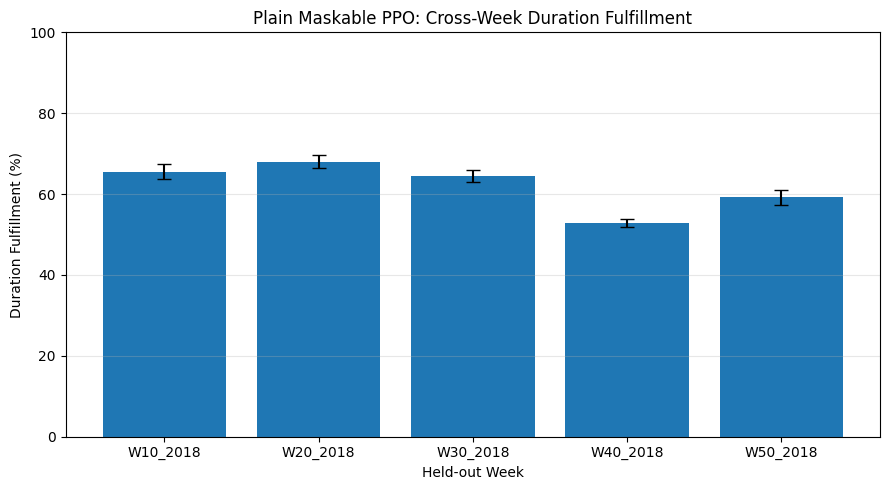

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    summary_df["held_out_week"],
    summary_df["mean_duration_fulfillment"] * 100,
    yerr=summary_df["std_duration_fulfillment"] * 100,
    capsize=5
)

plt.xlabel("Held-out Week")
plt.ylabel("Duration Fulfillment (%)")
plt.title("Plain Maskable PPO: Cross-Week Duration Fulfillment")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "cross_week_duration_fulfillment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Minimum satisfaction across held-out weeks

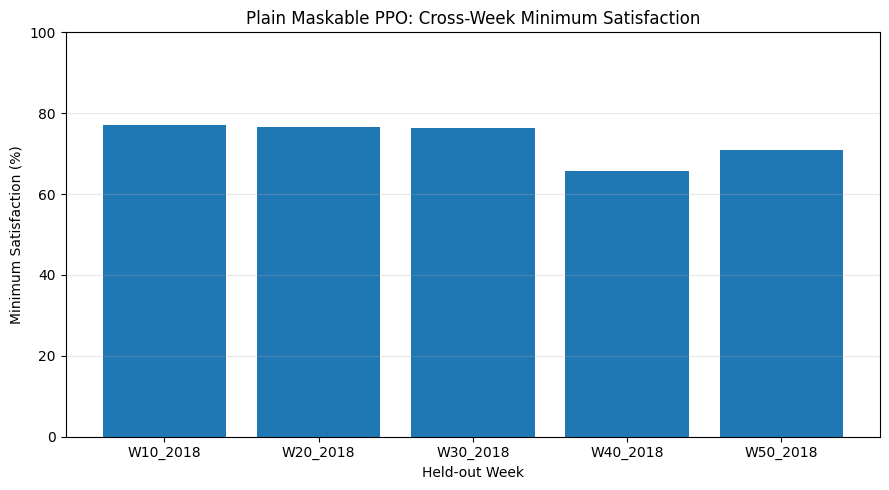

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    summary_df["held_out_week"],
    summary_df["mean_minimum_satisfaction"] * 100)

plt.xlabel("Held-out Week")
plt.ylabel("Minimum Satisfaction (%)")
plt.title("Plain Maskable PPO: Cross-Week Minimum Satisfaction")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "cross_week_minimum_satisfaction.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

Evaluation-seed variability

/tmp/ipykernel_6744/2439454953.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=weeks)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


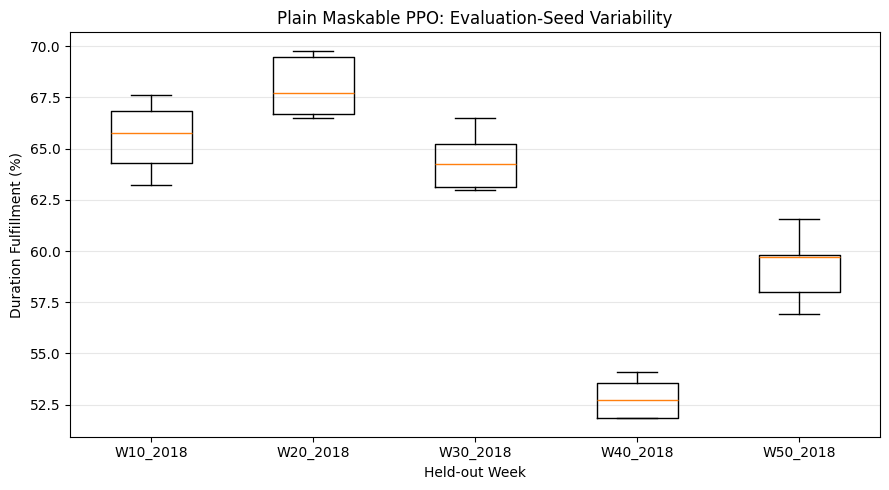

In [ ]:
plt.figure(figsize=(9, 5))

weeks = sorted(cross_week_df["held_out_week"].unique())

data = [
    cross_week_df.loc[
        cross_week_df["held_out_week"] == week,
        "duration_fulfillment"
    ] * 100
    for week in weeks
]

plt.boxplot(data, labels=weeks)

plt.xlabel("Held-out Week")
plt.ylabel("Duration Fulfillment (%)")
plt.title("Plain Maskable PPO: Evaluation-Seed Variability")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "cross_week_seed_variability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Evaluation runtime distribution

/tmp/ipykernel_6744/2457491619.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


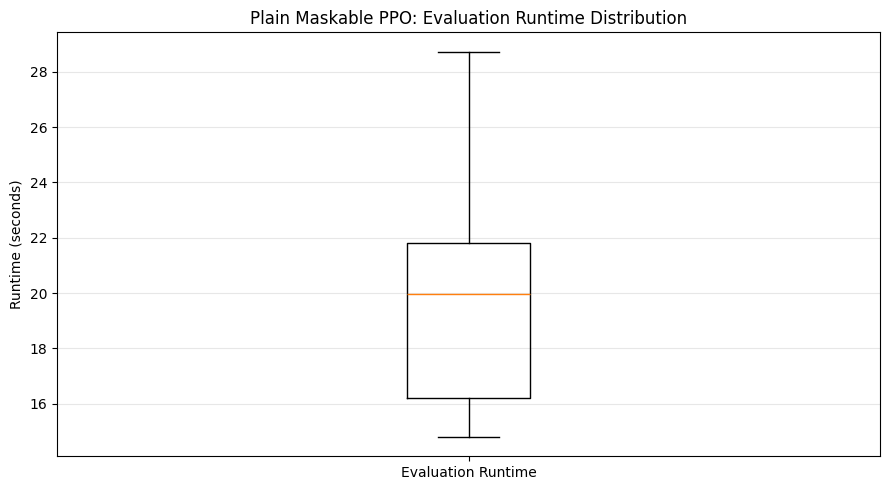

In [ ]:
plt.figure(figsize=(9, 5))

plt.boxplot(
    cross_week_df["runtime_seconds"],
    labels=["Evaluation Runtime"]
)

plt.ylabel("Runtime (seconds)")
plt.title("Plain Maskable PPO: Evaluation Runtime Distribution")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "cross_week_runtime_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Mean Episode Reward (PPO vs Baseline)

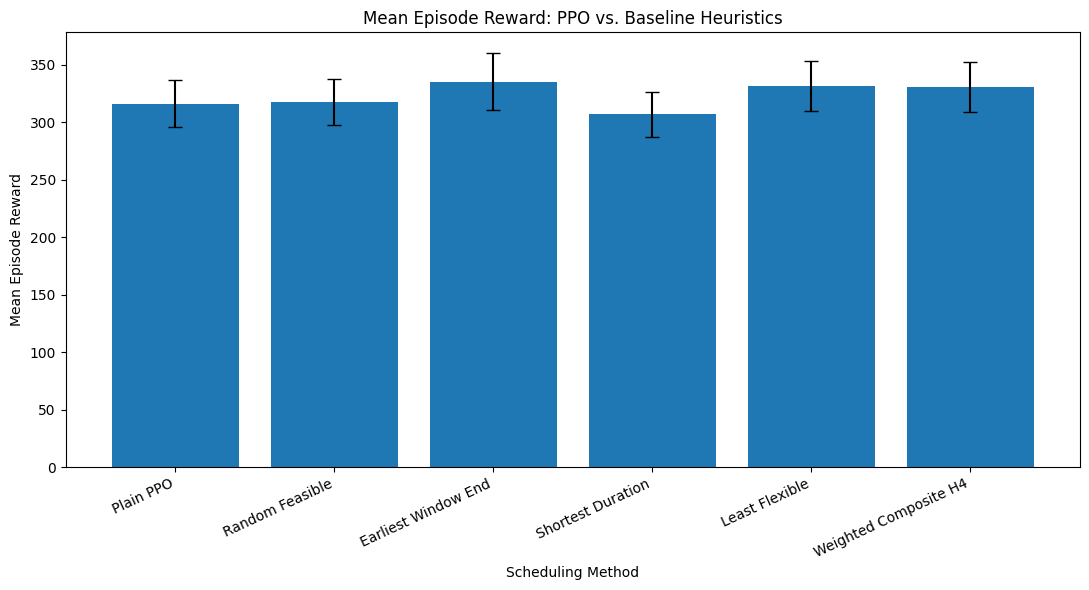

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

methods = [
    "Plain PPO",
    "Random Feasible",
    "Earliest Window End",
    "Shortest Duration",
    "Least Flexible",
    "Weighted Composite H4"
]

rewards = [316.198, 317.334, 335.314, 306.892, 331.076, 330.769]
stds = [20.133, 19.910, 24.856, 19.702, 21.756, 21.568]

plt.figure(figsize=(11, 6))
plt.bar(methods, rewards, yerr=stds, capsize=5)

plt.title("Mean Episode Reward: PPO vs. Baseline Heuristics")
plt.ylabel("Mean Episode Reward")
plt.xlabel("Scheduling Method")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

figures_dir = Path(
    "/content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_figures"
)

plt.savefig(
    figures_dir / "ppo_vs_baseline_episode_reward.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Final deliverable check

In [ ]:
from pathlib import Path

OUTPUT_DIR = Path("/content/drive/MyDrive/BEE/member2_plain_ppo")

required_files = [
    "plain_ppo_final_evaluation.csv",
    "plain_ppo_validation_summary.csv",
    "plain_ppo_cross_week_results.csv",
    "plain_ppo_cross_week_summary.csv",
    "plain_ppo_configuration.json",
    "plain_ppo_training_runs.csv",
    "plain_ppo_validation_results.csv",
]

print("FINAL DELIVERABLE CHECK\n")

for filename in required_files:
    path = OUTPUT_DIR / filename
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{filename}: {status}")

print("\nFIGURES:")
figure_dir = OUTPUT_DIR / "plain_ppo_figures"

if figure_dir.exists():
    for file in sorted(figure_dir.glob("*.png")):
        print(file.name)
else:
    print("Figure directory not found")

print("\nMODEL DIRECTORIES:")
for folder in ["plain_ppo_models", "plain_ppo_cross_week_models"]:
    path = OUTPUT_DIR / folder
    print(f"{folder}: {'FOUND' if path.exists() else 'MISSING'}")

FINAL DELIVERABLE CHECK

plain_ppo_final_evaluation.csv: FOUND
plain_ppo_validation_summary.csv: FOUND
plain_ppo_cross_week_results.csv: FOUND
plain_ppo_cross_week_summary.csv: FOUND
plain_ppo_configuration.json: FOUND
plain_ppo_training_runs.csv: FOUND
plain_ppo_validation_results.csv: FOUND

FIGURES:
cross_week_duration_fulfillment.png
cross_week_minimum_satisfaction.png
cross_week_runtime_distribution.png
cross_week_seed_variability.png

MODEL DIRECTORIES:
plain_ppo_models: FOUND
plain_ppo_cross_week_models: FOUND


# Training Curves

In [ ]:
from pathlib import Path

OUTPUT_DIR = Path("/content/drive/MyDrive/BEE/member2_plain_ppo")

print("Searching for training logs...\n")

for path in OUTPUT_DIR.rglob("*"):
    if path.is_file() and (
        path.suffix.lower() in [".csv", ".log", ".zip"]
        or "monitor" in path.name.lower()
        or "progress" in path.name.lower()
        or "tensorboard" in path.name.lower()
    ):
        print(path.relative_to(OUTPUT_DIR))

Searching for training logs...

plain_ppo_final_evaluation.csv
plain_ppo_validation_summary.csv
plain_ppo_cross_week_summary.csv
plain_ppo_cross_week_results.csv
plain_ppo_validation_results.csv
plain_ppo_training_runs.csv
plain_ppo_models/plain_ppo_500.zip
plain_ppo_models/plain_ppo_1000.zip
plain_ppo_models/plain_ppo_1500.zip
plain_ppo_models/plain_ppo_2000.zip
plain_ppo_models/plain_ppo_2500.zip
plain_ppo_models/plain_ppo_3000.zip
plain_ppo_models/plain_ppo_3500.zip
plain_ppo_models/plain_ppo_4000.zip
plain_ppo_models/plain_ppo_4500.zip
plain_ppo_models/plain_ppo_5000.zip
plain_ppo_models/plain_ppo_5500.zip
plain_ppo_models/plain_ppo_6000.zip
plain_ppo_models/plain_ppo_6500.zip
plain_ppo_models/plain_ppo_7000.zip
plain_ppo_models/plain_ppo_7500.zip
plain_ppo_models/plain_ppo_8000.zip
plain_ppo_models/plain_ppo_8500.zip
plain_ppo_models/plain_ppo_9000.zip
plain_ppo_models/plain_ppo_9500.zip
plain_ppo_models/plain_ppo_10000.zip
plain_ppo_models/plain_ppo_10500.zip
plain_ppo_models/pla

In [ ]:
import pandas as pd
from pathlib import Path

progress_path = OUTPUT_DIR / "plain_ppo_validation" / "plain_ppo_validation_progress.csv"

progress_df = pd.read_csv(progress_path)

print("Columns:")
print(progress_df.columns.tolist())

print("\nFirst 10 rows:")
display(progress_df.head(10))

print("\nLast 10 rows:")
display(progress_df.tail(10))

print("\nDataset shape:", progress_df.shape)

Columns:
['week_key', 'number_of_requests', 'scheduled_requests', 'allocated_hours', 'duration_fulfillment', 'minimum_satisfaction_rate', 'full_satisfaction_rate', 'unmet_hours', 'mission_fairness', 'constraint_violations', 'method', 'seed', 'episode_reward', 'steps', 'runtime_seconds', 'timesteps', 'validation_duplicate_request_violations', 'validation_duration_violations', 'validation_visibility_violations', 'validation_maintenance_violations', 'validation_antenna_overlap_violations', 'validation_resource_violations', 'validation_constraint_violations']

First 10 rows:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,week_key,number_of_requests,scheduled_requests,allocated_hours,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness,constraint_violations,...,steps,runtime_seconds,timesteps,validation_duplicate_request_violations,validation_duration_violations,validation_visibility_violations,validation_maintenance_violations,validation_antenna_overlap_violations,validation_resource_violations,validation_constraint_violations
0,W40_2018,333,221,952.760278,0.548604,0.663664,0.573574,783.939722,0.864956,0,...,221,19.452506,500,0,0,0,0,0,0,0
1,W40_2018,333,219,944.924722,0.544092,0.657658,0.561562,791.775278,0.863630,0,...,219,19.399132,1000,0,0,0,0,0,0,0
2,W40_2018,333,222,958.647222,0.551994,0.666667,0.558559,778.052778,0.871846,0,...,222,18.933291,1500,0,0,0,0,0,0,0
3,W40_2018,333,219,947.123889,0.545358,0.657658,0.558559,789.576111,0.886244,0,...,219,18.675668,2000,0,0,0,0,0,0,0
4,W40_2018,333,219,928.670833,0.534733,0.657658,0.552553,808.029167,0.880219,0,...,219,18.960766,2500,0,0,0,0,0,0,0
5,W40_2018,333,217,919.379444,0.529383,0.651652,0.561562,817.320556,0.868934,0,...,217,18.513605,3000,0,0,0,0,0,0,0
6,W40_2018,333,218,945.480278,0.544412,0.654655,0.546547,791.219722,0.851886,0,...,218,18.015133,3500,0,0,0,0,0,0,0
7,W40_2018,333,219,947.138333,0.545367,0.657658,0.564565,789.561667,0.888465,0,...,219,18.028154,4000,0,0,0,0,0,0,0
8,W40_2018,333,220,952.929722,0.548701,0.660661,0.558559,783.770278,0.858807,0,...,220,18.809594,4500,0,0,0,0,0,0,0
9,W40_2018,333,220,936.297778,0.539125,0.660661,0.573574,800.402222,0.867912,0,...,220,18.428408,5000,0,0,0,0,0,0,0



Last 10 rows:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,week_key,number_of_requests,scheduled_requests,allocated_hours,duration_fulfillment,minimum_satisfaction_rate,full_satisfaction_rate,unmet_hours,mission_fairness,constraint_violations,...,steps,runtime_seconds,timesteps,validation_duplicate_request_violations,validation_duration_violations,validation_visibility_violations,validation_maintenance_violations,validation_antenna_overlap_violations,validation_resource_violations,validation_constraint_violations
40,W40_2018,333,211,917.560000,0.528335,0.633634,0.531532,819.140000,0.872384,0,...,211,19.072354,20500,0,0,0,0,0,0,0
41,W40_2018,333,212,920.905000,0.530261,0.636637,0.534535,815.795000,0.871096,0,...,212,19.431425,21000,0,0,0,0,0,0,0
42,W40_2018,333,211,903.191389,0.520062,0.633634,0.534535,833.508611,0.868906,0,...,211,18.016879,21500,0,0,0,0,0,0,0
43,W40_2018,333,210,903.874444,0.520455,0.630631,0.522523,832.825556,0.865267,0,...,210,17.825997,22000,0,0,0,0,0,0,0
44,W40_2018,333,210,889.601111,0.512236,0.630631,0.537538,847.098889,0.871344,0,...,210,18.261829,22500,0,0,0,0,0,0,0
45,W40_2018,333,212,883.906389,0.508957,0.636637,0.546547,852.793611,0.861523,0,...,212,18.703912,23000,0,0,0,0,0,0,0
46,W40_2018,333,213,902.440278,0.519629,0.639640,0.543544,834.259722,0.864882,0,...,213,17.872891,23500,0,0,0,0,0,0,0
47,W40_2018,333,213,904.954722,0.521077,0.639640,0.534535,831.745278,0.867349,0,...,213,17.728942,24000,0,0,0,0,0,0,0
48,W40_2018,333,212,897.618333,0.516853,0.636637,0.543544,839.081667,0.859461,0,...,212,17.780829,24500,0,0,0,0,0,0,0
49,W40_2018,333,214,918.061944,0.528624,0.642643,0.537538,818.638056,0.879628,0,...,214,18.022514,25000,0,0,0,0,0,0,0



Dataset shape: (50, 23)


Validation duration fulfillment over training timesteps.

Validation episode reward over training timesteps.

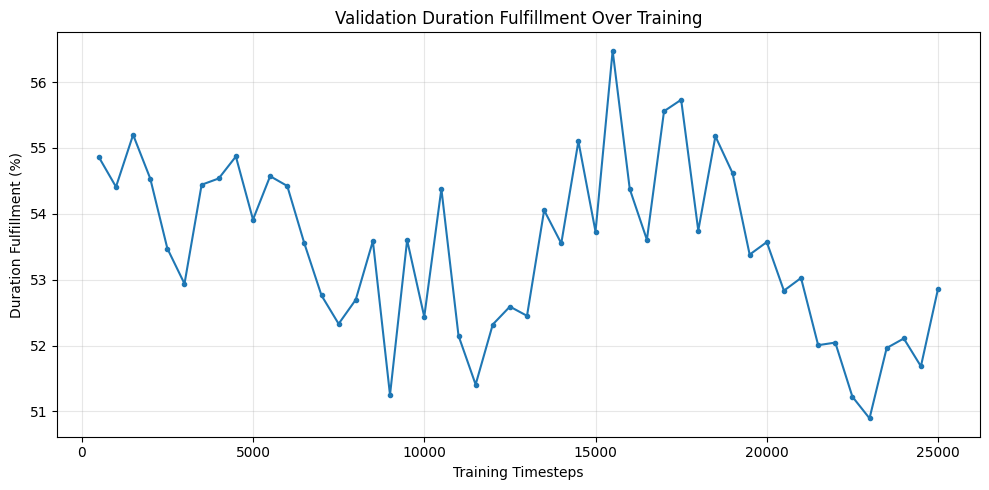

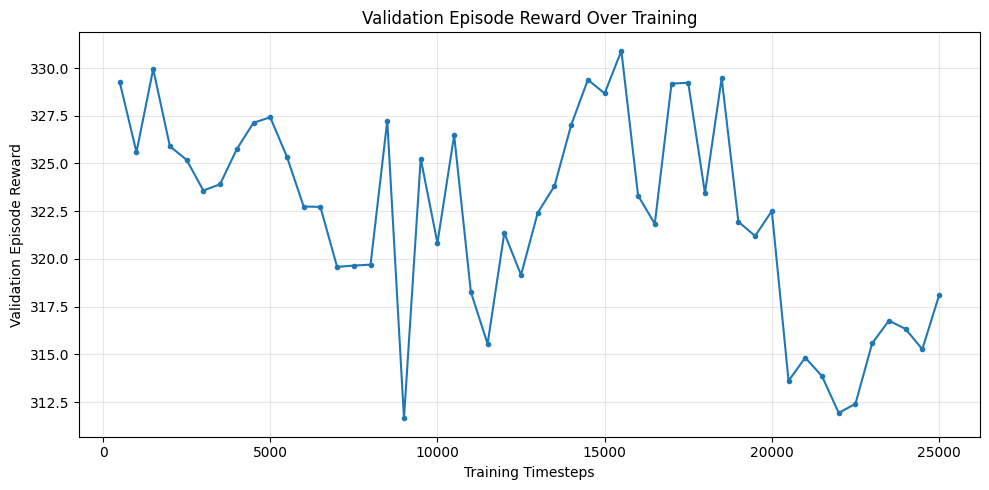

Both figures saved successfully.


In [ ]:
import matplotlib.pyplot as plt

FIGURE_DIR = OUTPUT_DIR / "plain_ppo_figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

progress_df = progress_df.sort_values("timesteps")

# Figure 1: Validation duration fulfillment
plt.figure(figsize=(10, 5))
plt.plot(
    progress_df["timesteps"],
    progress_df["duration_fulfillment"] * 100,
    marker="o",
    markersize=3
)
plt.xlabel("Training Timesteps")
plt.ylabel("Duration Fulfillment (%)")
plt.title("Validation Duration Fulfillment Over Training")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "validation_fulfillment_over_timesteps.png", dpi=300)
plt.show()

# Figure 2: Validation episode reward
plt.figure(figsize=(10, 5))
plt.plot(
    progress_df["timesteps"],
    progress_df["episode_reward"],
    marker="o",
    markersize=3
)
plt.xlabel("Training Timesteps")
plt.ylabel("Validation Episode Reward")
plt.title("Validation Episode Reward Over Training")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "validation_episode_reward_over_timesteps.png", dpi=300)
plt.show()

print("Both figures saved successfully.")

Selected: /content/drive/MyDrive/BEE/member2_plain_ppo/tensorboard/MaskablePPO_2/events.out.tfevents.1793628773.0058441454d5.687.1
Diagnostic records: 97


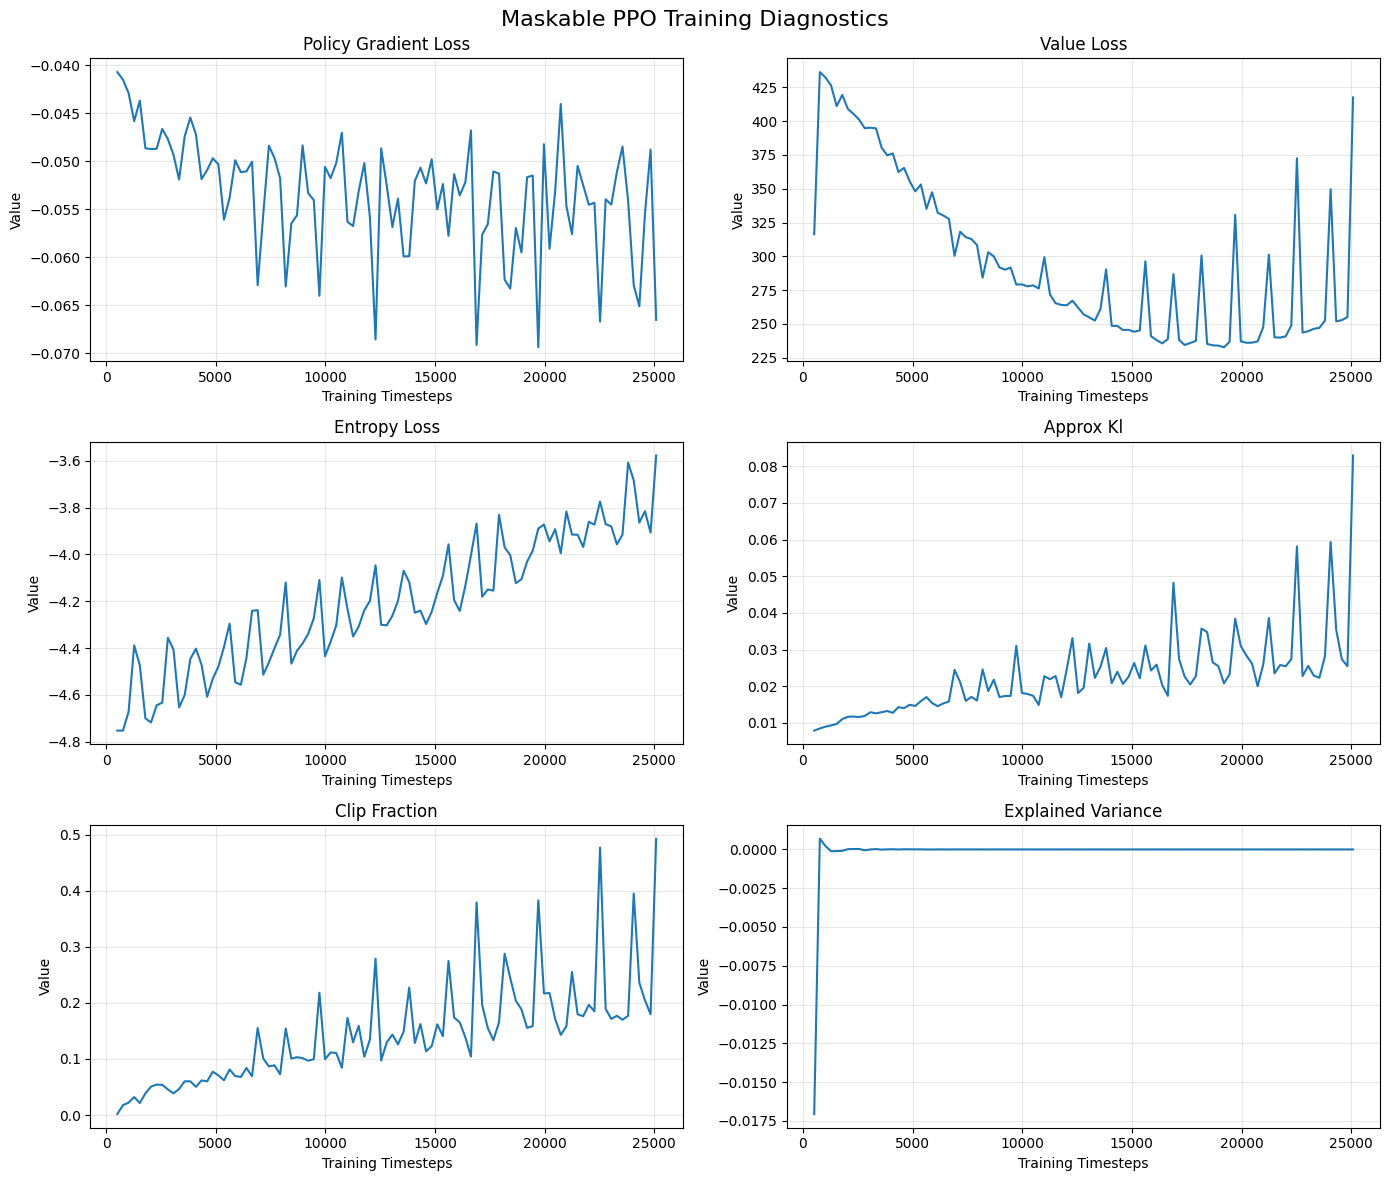


Saved: /content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_figures/ppo_training_diagnostics.png


In [ ]:
from pathlib import Path
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
import matplotlib.pyplot as plt

TB_DIR = OUTPUT_DIR / "tensorboard"
FIGURE_DIR = OUTPUT_DIR / "plain_ppo_figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

event_files = list(TB_DIR.rglob("events.out.tfevents.*"))

best_file = None
best_acc = None
best_count = 0

for file in event_files:
    acc = EventAccumulator(str(file))
    acc.Reload()

    tags = acc.Tags()["scalars"]

    if "train/value_loss" in tags:
        count = len(acc.Scalars("train/value_loss"))

        if count > best_count:
            best_count = count
            best_file = file
            best_acc = acc

if best_file is None:
    print("No PPO diagnostic metrics found.")
else:
    print("Selected:", best_file)
    print("Diagnostic records:", best_count)

    metrics = [
        "train/policy_gradient_loss",
        "train/value_loss",
        "train/entropy_loss",
        "train/approx_kl",
        "train/clip_fraction",
        "train/explained_variance"
    ]

    fig, axes = plt.subplots(3, 2, figsize=(14, 12))

    for ax, metric in zip(axes.flatten(), metrics):
        events = best_acc.Scalars(metric)

        steps = [e.step for e in events]
        values = [e.value for e in events]

        ax.plot(steps, values)
        ax.set_title(metric.replace("train/", "").replace("_", " ").title())
        ax.set_xlabel("Training Timesteps")
        ax.set_ylabel("Value")
        ax.grid(True, alpha=0.3)

    plt.suptitle("Maskable PPO Training Diagnostics", fontsize=16)
    plt.tight_layout()

    diagnostic_path = FIGURE_DIR / "ppo_training_diagnostics.png"
    plt.savefig(diagnostic_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("\nSaved:", diagnostic_path)

# Report

In [ ]:
report = """
# Member 2: Plain Maskable PPO

## 1. Objective

This experiment investigates whether Maskable Proximal Policy Optimization (PPO)
can learn a request-selection policy for offline ground-station scheduling.

The plain PPO model uses the standard scheduling observations without
bee-inspired features. Invalid actions are excluded through action masking.

## 2. Environment and Observation Space

The observation space contains 3,001 features:

- 333 request slots, each represented by 9 features.
- 4 episode-level global features.

The request-level features include:

1. Scheduled indicator
2. Feasibility indicator
3. Requested duration
4. Minimum duration
5. Setup time
6. Teardown time
7. Number of resource options
8. Remaining-placement ratio
9. Earliest feasible end time

The action space is Discrete(333), corresponding to the maximum
number of request slots.

## 3. Reward Function

The shared reward function is:

Reward = Allocated-duration fraction
         + 0.5 × Minimum-duration indicator

This reward encourages the agent to allocate requested observation
duration while also satisfying minimum-duration requirements.

## 4. PPO Configuration

The model uses the following hyperparameters:

| Parameter | Value |
|---|---:|
| Learning rate | 0.0003 |
| n_steps | 256 |
| Batch size | 64 |
| Number of epochs | 10 |
| Gamma | 0.99 |
| GAE lambda | 0.95 |
| Clip range | 0.2 |
| Entropy coefficient | 0.01 |
| Value function coefficient | 0.5 |
| Maximum gradient norm | 0.5 |
| Training seed | 42 |
| Target timesteps | 25,000 |
| Actual timesteps | 25,088 |

The actual number of timesteps is slightly higher than the target because
PPO collects complete rollouts of 256 steps.

## 5. Experimental Design

### 5.1 Canonical Training and Validation

The canonical experiment used:

- Training weeks: W10_2018, W20_2018, W30_2018
- Validation week: W40_2018
- Training seed: 42
- Evaluation seeds: 1001, 2002, 3003, 4004, 5005

The model was trained for 25,088 timesteps.

### 5.2 Cross-Week Evaluation

To evaluate generalization across different weeks, five independent
models were trained using five-fold cross-week evaluation.

Each fold held out one week for evaluation and trained on the remaining
four weeks.

| Fold | Training weeks | Held-out week |
|---|---|---|
| 1 | W20, W30, W40, W50 | W10 |
| 2 | W10, W30, W40, W50 | W20 |
| 3 | W10, W20, W40, W50 | W30 |
| 4 | W10, W20, W30, W50 | W40 |
| 5 | W10, W20, W30, W40 | W50 |

Each fold used training seed 42 and 25,088 timesteps.
Each held-out week was evaluated using five evaluation seeds,
resulting in 25 cross-week evaluation runs.

## 6. Canonical Validation Results

The canonical model was evaluated on W40_2018 using five seeds.

| Metric | Mean |
|---|---:|
| Duration fulfillment | 52.64% |
| Minimum satisfaction | 65.29% |
| Full satisfaction | 55.43% |
| Mission fairness | 86.22% |
| Evaluation runtime | 18.77 seconds |
| Constraint violations | 0 |

All five evaluated schedules had zero constraint violations.

## 7. Cross-Week Results

The following table reports the mean results across five evaluation
seeds for each held-out week.

| Held-out week | Duration fulfillment | Minimum satisfaction | Full satisfaction | Mission fairness |
|---|---:|---:|---:|---:|
| W10 | 65.56% | 76.96% | 70.35% | 92.56% |
| W20 | 68.04% | 76.60% | 70.20% | 92.66% |
| W30 | 64.41% | 76.45% | 69.49% | 91.74% |
| W40 | 52.81% | 65.77% | 54.96% | 86.57% |
| W50 | 59.20% | 70.84% | 67.05% | 90.16% |

### Overall Cross-Week Performance

| Metric | Overall mean |
|---|---:|
| Duration fulfillment | 62.00% |
| Minimum satisfaction | 73.32% |
| Full satisfaction | 66.41% |
| Mission fairness | 90.74% |
| Evaluation runtime | 19.81 seconds |
| Constraint violations | 0 across 25 runs |

W20 achieved the highest mean duration fulfillment at 68.04%.
W10 achieved the highest mean minimum satisfaction at 76.96%.
W40 had the lowest performance across the main fulfillment metrics.

The standard deviation of duration fulfillment across evaluation seeds
ranged from approximately 1.00 to 1.79 percentage points across the
five held-out weeks.

All 25 evaluated schedules had zero constraint violations.

## 8. Training Runtime

The canonical training run required approximately 2,459.23 seconds.

The five cross-week training runs required approximately:

| Fold | Training runtime (seconds) |
|---|---:|
| 1 | 1,942.63 |
| 2 | 1,888.05 |
| 3 | 1,901.77 |
| 4 | 1,816.27 |
| 5 | 1,854.54 |

The total cross-week training runtime was approximately 9,403.26 seconds.

## 9. Figures

The following figures were generated and saved in the
plain_ppo_figures directory:

1. cross_week_duration_fulfillment.png
2. cross_week_minimum_satisfaction.png
3. cross_week_seed_variability.png
4. cross_week_runtime_distribution.png

These figures illustrate differences in fulfillment across held-out
weeks, minimum-duration satisfaction, evaluation-seed variability,
and evaluation runtime.

## 10. Discussion

The results show that plain Maskable PPO learned a feasible scheduling
policy across all five held-out weeks.

The overall cross-week duration fulfillment was 62.00%, while minimum
satisfaction reached 73.32%. Mission fairness averaged 90.74%.

The model produced zero constraint violations in all 25 cross-week
evaluation runs and all five canonical validation runs. This indicates
that action masking and the environment's scheduling constraints
worked together to produce valid schedules.

Performance varied between weeks. W20 achieved the strongest duration
fulfillment, whereas W40 was more challenging, with lower duration
fulfillment and minimum satisfaction. This variation suggests that
the characteristics of the held-out week influence scheduling
performance.

The evaluation-seed results also show some variability, although the
standard deviation of duration fulfillment remained relatively small
within each fold.

## 11. Limitations

This experiment evaluates the plain Maskable PPO approach.
It does not, by itself, establish that PPO outperforms random or
conventional scheduling heuristics. That conclusion requires
comparison with the corresponding baseline results under the same
evaluation conditions.

The experiment also uses one training seed per model and five
evaluation seeds. Additional training seeds could provide stronger
evidence about training stability.

## 12. Conclusion

Plain Maskable PPO successfully generated feasible schedules across
the canonical validation experiment and all five cross-week folds.

Across 25 cross-week evaluation runs, it achieved 62.00% mean duration
fulfillment, 73.32% mean minimum satisfaction, and 90.74% mean mission
fairness, with zero constraint violations.

These results provide a baseline for comparing the plain PPO policy
with other scheduling approaches and with PPO variants that incorporate
additional features.
"""

report_path = OUTPUT_DIR / "plain_ppo_report_section.md"

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

print("Report saved successfully:")
print(report_path)
print("Report size:", report_path.stat().st_size, "bytes")

Report saved successfully:
/content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_report_section.md
Report size: 6870 bytes


In [ ]:

import re
from pathlib import Path

REPORT_PATH = OUTPUT_DIR / "plain_ppo_report_section.md"

updated_sections = r"""
## 9. Figures and Training Analysis

The following figures summarize the training behavior, validation
performance, cross-week results, and computational performance of
the plain Maskable PPO approach.

### 9.1 Cross-Week Evaluation

1. `cross_week_duration_fulfillment.png`
   - Compares duration fulfillment across the five held-out weeks.

2. `cross_week_minimum_satisfaction.png`
   - Shows minimum-duration satisfaction across the five folds.

3. `cross_week_seed_variability.png`
   - Illustrates performance variability across the five evaluation
     seeds within each fold.

4. `cross_week_runtime_distribution.png`
   - Shows the distribution of evaluation runtime across the
     cross-week experiments.

### 9.2 Canonical Training and Validation

5. `validation_fulfillment_over_timesteps.png`
   - Shows validation duration fulfillment at checkpoints from
     500 to 25,000 timesteps.
   - Fulfillment fluctuated throughout training rather than
     increasing consistently.

6. `validation_episode_reward_over_timesteps.png`
   - Shows validation episode reward across training checkpoints.
   - The results demonstrate fluctuations in validation reward
     rather than a steady improvement.

### 9.3 PPO Training Diagnostics

7. `ppo_training_diagnostics.png`
   - Presents six PPO training metrics:
     - Policy gradient loss
     - Value loss
     - Entropy loss
     - Approximate KL divergence
     - Clip fraction
     - Explained variance

These metrics provide additional information about policy
optimization, value-function learning, exploration, and the
stability of PPO updates.

The diagnostic figure was generated from the TensorBoard logs
of the canonical model trained on W10, W20, and W30 using seed 42.
It contains 97 recorded training updates, covering timesteps
512 to 25,088.

The diagnostic curves represent the canonical training run only.
Equivalent diagnostic histories were not recovered for the five
cross-week training runs.

## 10. Discussion

The results show that plain Maskable PPO learned a feasible
scheduling policy across all five held-out weeks.

The overall cross-week duration fulfillment was 62.00%, while
minimum satisfaction reached 73.32%. Mission fairness averaged
90.74%.

The model produced zero constraint violations in all 25
cross-week evaluation runs and all five canonical validation
runs. This indicates that action masking and the environment's
scheduling constraints worked together to produce valid schedules.

Performance varied between weeks. W20 achieved the strongest
duration fulfillment, whereas W40 was more challenging, with
lower duration fulfillment and minimum satisfaction. This
variation suggests that the characteristics of the held-out
week influence scheduling performance.

The evaluation-seed results also show some variability, although
the standard deviation of duration fulfillment remained relatively
small within each fold.

The canonical validation curves showed fluctuations in both
duration fulfillment and episode reward. Therefore, validation
performance did not improve consistently throughout training.

The PPO diagnostic metrics provide a complementary view of the
optimization process. Policy gradient loss and value loss describe
the policy and value-function optimization objectives, while
entropy loss, approximate KL, and clip fraction provide information
about exploration and policy updates. Explained variance provides
an indication of value-function prediction quality.

These training diagnostics should be interpreted alongside
validation and cross-week evaluation results rather than being
treated as direct measures of scheduling performance.

## 11. Limitations

This experiment evaluates the plain Maskable PPO approach.
It does not, by itself, establish that PPO outperforms random or
conventional scheduling heuristics. That conclusion requires
comparison with the corresponding baseline results under the same
evaluation conditions.

The experiment also uses one training seed per model and five
evaluation seeds. Additional training seeds could provide stronger
evidence about training stability.

Furthermore, the detailed TensorBoard diagnostic history was
available for the canonical training run but was not recovered
for the five cross-week models.

Although validation performance fluctuated during training,
the final model was evaluated independently across five
cross-week folds to assess its generalization performance.

## 12. Conclusion

Plain Maskable PPO successfully generated feasible schedules
across the canonical validation experiment and all five
cross-week folds.

Across 25 cross-week evaluation runs, it achieved 62.00% mean
duration fulfillment, 73.32% mean minimum satisfaction, and
90.74% mean mission fairness, with zero constraint violations.

The training and validation figures provide insight into the
learning process, while the cross-week experiments demonstrate
the model's performance across different held-out weeks.

These results provide a baseline for comparing the plain PPO
policy with other scheduling approaches and with PPO variants
that incorporate additional features.
"""

if REPORT_PATH.exists():
    original_report = REPORT_PATH.read_text(encoding="utf-8")

    match = re.search(r"(?m)^## 9\.", original_report)

    if match:
        final_report = original_report[:match.start()] + updated_sections.lstrip()
    else:
        final_report = original_report.rstrip() + "\n\n" + updated_sections.lstrip()

    REPORT_PATH.write_text(final_report, encoding="utf-8")

    print("Report updated successfully.")
    print("Location:", REPORT_PATH)
    print("\nUpdated report sections:")
    print(final_report[final_report.find("## 9."):])
else:
    print("Report file not found. No changes were made.")


Report updated successfully.
Location: /content/drive/MyDrive/BEE/member2_plain_ppo/plain_ppo_report_section.md

Updated report sections:
## 9. Figures and Training Analysis

The following figures summarize the training behavior, validation
performance, cross-week results, and computational performance of
the plain Maskable PPO approach.

### 9.1 Cross-Week Evaluation

1. `cross_week_duration_fulfillment.png`
   - Compares duration fulfillment across the five held-out weeks.

2. `cross_week_minimum_satisfaction.png`
   - Shows minimum-duration satisfaction across the five folds.

3. `cross_week_seed_variability.png`
   - Illustrates performance variability across the five evaluation
     seeds within each fold.

4. `cross_week_runtime_distribution.png`
   - Shows the distribution of evaluation runtime across the
     cross-week experiments.

### 9.2 Canonical Training and Validation

5. `validation_fulfillment_over_timesteps.png`
   - Shows validation duration fulfillment at checkpoint